In [1]:
# Import required libraries for hotel booking data analysis and preprocessing
import numpy as np
import pandas as pd

In [2]:
# Load the hotel booking dataset into a pandas DataFrame
df = pd.read_csv("hotel_bookings.csv")

In [3]:
# Display the first five rows of the dataset
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
# Check the number of rows and columns in the dataset
df.shape

(119390, 32)

In [5]:
# Display dataset information, including data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [6]:
# Check the number of missing values in each column
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [7]:
# Calculate the percentage of missing values in each column
missing_percentage = df.isnull().mean() * 100
missing_percentage

hotel                              0.000000
is_canceled                        0.000000
lead_time                          0.000000
arrival_date_year                  0.000000
arrival_date_month                 0.000000
arrival_date_week_number           0.000000
arrival_date_day_of_month          0.000000
stays_in_weekend_nights            0.000000
stays_in_week_nights               0.000000
adults                             0.000000
children                           0.003350
babies                             0.000000
meal                               0.000000
country                            0.408744
market_segment                     0.000000
distribution_channel               0.000000
is_repeated_guest                  0.000000
previous_cancellations             0.000000
previous_bookings_not_canceled     0.000000
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                    0.000000
deposit_type                    

In [8]:
# Display only columns with missing values
missing_percentage[missing_percentage > 0]

children     0.003350
country      0.408744
agent       13.686238
company     94.306893
dtype: float64

In [9]:
# Display the first 10 unique values in each column

print("Children:", df['children'].unique()[:10])
print("Country:", df['country'].unique()[:10])
print("Agent:", df['agent'].unique()[:10])
print("Company:", df['company'].unique()[:10])

Children: [ 0.  1.  2. 10.  3. nan]
Country: ['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' nan 'ROU' 'NOR' 'OMN']
Agent: [ nan 304. 240. 303.  15. 241.   8. 250. 115.   5.]
Company: [ nan 110. 113. 270. 178. 240. 154. 144. 307. 268.]


In [10]:
# Count the number of unique values in each column
print("Children:", df['children'].nunique())
print("Country:", df['country'].nunique())
print("Agent:", df['agent'].nunique())
print("Company:", df['company'].nunique())

Children: 5
Country: 177
Agent: 333
Company: 352


In [11]:
# Count the number of bookings for each company
df['company'].value_counts()

company
40.0     927
223.0    784
67.0     267
45.0     250
153.0    215
        ... 
104.0      1
531.0      1
160.0      1
413.0      1
386.0      1
Name: count, Length: 352, dtype: int64

In [12]:
# Count bookings with a company ID
print("Non-missing:", df['company'].notna().sum())

# Count unique company IDs
print("Unique companies:", df['company'].nunique())

# Count bookings without a company ID
print("Missing:", df['company'].isna().sum())

Non-missing: 6797
Unique companies: 352
Missing: 112593


In [13]:
# Count bookings with and without an agent ID
print("Non-missing:", df['agent'].notna().sum())
print("Unique agents:", df['agent'].nunique())
print("Missing:", df['agent'].isna().sum())

Non-missing: 103050
Unique agents: 333
Missing: 16340


In [14]:
# Count bookings for each agent
df['agent'].value_counts().head(10)

agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
6.0       3290
250.0     2870
241.0     1721
28.0      1666
8.0       1514
Name: count, dtype: int64

In [15]:
# Calculate the percentage of bookings for the top 10 agents
top_10_agents = df['agent'].value_counts().head(10)

top_10_agents_percentage = top_10_agents / df['agent'].notna().sum() * 100

top_10_agents_percentage

agent
9.0      31.015041
240.0    13.509947
1.0       6.978166
14.0      3.532266
7.0       3.434255
6.0       3.192625
250.0     2.785056
241.0     1.670063
28.0      1.616691
8.0       1.469190
Name: count, dtype: float64

In [16]:
# Count bookings for each market segment
df['market_segment'].value_counts()

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

In [17]:
# Calculate the percentage of bookings for each market segment
market_segment_percentage = df['market_segment'].value_counts(normalize=True) * 100

market_segment_percentage

market_segment
Online TA        47.304632
Offline TA/TO    20.285619
Groups           16.593517
Direct           10.558673
Corporate         4.435045
Complementary     0.622330
Aviation          0.198509
Undefined         0.001675
Name: proportion, dtype: float64

In [18]:
# Calculate the cancellation rate for each market segment
cancellation_by_segment = df.groupby('market_segment')['is_canceled'].mean() * 100

cancellation_by_segment.sort_values(ascending=False)

market_segment
Undefined        100.000000
Groups            61.062036
Online TA         36.721143
Offline TA/TO     34.316033
Aviation          21.940928
Corporate         18.734655
Direct            15.341901
Complementary     13.055182
Name: is_canceled, dtype: float64

In [19]:
# Compare booking volume and cancellation rate by market segment
segment_analysis = df.groupby('market_segment').agg(
    bookings=('is_canceled', 'count'),
    cancellation_rate=('is_canceled', 'mean')
)

segment_analysis['cancellation_rate'] *= 100

segment_analysis.sort_values('cancellation_rate', ascending=False)

,bookings,cancellation_rate
market_segment,,
Undefined,2,100.000000
Groups,19811,61.062036
Online TA,56477,36.721143
Offline TA/TO,24219,34.316033
Aviation,237,21.940928
Corporate,5295,18.734655
Direct,12606,15.341901
Complementary,743,13.055182


In [20]:
# Count canceled bookings for each market segment
canceled_by_segment = df.groupby('market_segment')['is_canceled'].sum()

canceled_by_segment.sort_values(ascending=False)

market_segment
Online TA        20739
Groups           12097
Offline TA/TO     8311
Direct            1934
Corporate          992
Complementary       97
Aviation            52
Undefined            2
Name: is_canceled, dtype: int64

In [21]:
# Summarize total, canceled, and remaining bookings by market segment
segment_summary = df.groupby('market_segment').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate the number of non-canceled bookings
segment_summary['remaining_bookings'] = (
    segment_summary['total_bookings']
    - segment_summary['canceled_bookings']
)

# Sort by total bookings
segment_summary = segment_summary.sort_values(
    'total_bookings',
    ascending=False
)

segment_summary

,total_bookings,canceled_bookings,remaining_bookings
market_segment,,,
Online TA,56477,20739,35738
Offline TA/TO,24219,8311,15908
Groups,19811,12097,7714
Direct,12606,1934,10672
Corporate,5295,992,4303
Complementary,743,97,646
Aviation,237,52,185
Undefined,2,2,0


### Cancellation Analysis by Market Segment

The Groups segment has the highest meaningful cancellation rate at approximately 61.06%. Online TA has the largest number of canceled bookings, with 20,739 cancellations, partly reflecting its high booking volume. Direct bookings have a lower cancellation rate of approximately 15.34%.

These findings suggest that cancellation patterns differ across market segments. The Undefined segment has only two bookings, so its 100% cancellation rate should not be considered representative.

In [22]:
# Count bookings for each deposit type
df['deposit_type'].value_counts()

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

In [23]:
# Calculate the cancellation rate for each deposit type
cancellation_by_deposit = (
    df.groupby('deposit_type')['is_canceled'].mean() * 100
)

cancellation_by_deposit.sort_values(ascending=False)

deposit_type
Non Refund    99.362446
No Deposit    28.377022
Refundable    22.222222
Name: is_canceled, dtype: float64

In [24]:
# Summarize total, canceled, and non-canceled bookings by deposit type
deposit_summary = df.groupby('deposit_type').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate the number of non-canceled bookings
deposit_summary['non_canceled_bookings'] = (
    deposit_summary['total_bookings']
    - deposit_summary['canceled_bookings']
)

deposit_summary

,total_bookings,canceled_bookings,non_canceled_bookings
deposit_type,,,
No Deposit,104641,29694,74947
Non Refund,14587,14494,93
Refundable,162,36,126


### Cancellation Analysis by Deposit Type

Bookings with the Non Refund deposit type have the highest cancellation rate at approximately 99.36%, compared with 28.38% for No Deposit and 22.22% for Refundable bookings.

This is a strong association in the dataset, but it does not establish that the deposit type causes cancellations. The Refundable category contains only 162 bookings, so its cancellation rate should be interpreted cautiously.

In [25]:
# Count bookings for each hotel type
df['hotel'].value_counts()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

In [26]:
# Calculate the cancellation rate for each hotel type
cancellation_by_hotel = (
    df.groupby('hotel')['is_canceled'].mean() * 100
)

cancellation_by_hotel.sort_values(ascending=False)

hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64

In [27]:
# Summarize bookings by hotel type
hotel_summary = df.groupby('hotel').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate non-canceled bookings
hotel_summary['non_canceled_bookings'] = (
    hotel_summary['total_bookings']
    - hotel_summary['canceled_bookings']
)

hotel_summary

# Calculate the cancellation rate as a percentage
hotel_summary['cancellation_rate_%'] = (
    hotel_summary['canceled_bookings']
    / hotel_summary['total_bookings'] * 100
)

hotel_summary

,total_bookings,canceled_bookings,non_canceled_bookings,cancellation_rate_%
hotel,,,,
City Hotel,79330,33102,46228,41.726963
Resort Hotel,40060,11122,28938,27.763355


### Cancellation Analysis by Hotel Type

The City Hotel recorded 79,330 bookings, with 33,102 cancellations and a cancellation rate of 41.73%. The Resort Hotel recorded 40,060 bookings, with 11,122 cancellations and a cancellation rate of 27.76%.

The City Hotel's cancellation rate was approximately 13.96 percentage points higher than that of the Resort Hotel. This finding suggests that cancellation management may require greater attention at the City Hotel. However, further analysis is needed to investigate the factors associated with this difference.

In [28]:
# Count bookings for each customer type
df['customer_type'].value_counts()

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

In [29]:
# Calculate the cancellation rate for each customer type
cancellation_by_customer = (
    df.groupby('customer_type')['is_canceled'].mean() * 100
)

# Sort customer types by cancellation rate in descending order
cancellation_by_customer.sort_values(ascending=False)

customer_type
Transient          40.746320
Contract           30.961727
Transient-Party    25.429868
Group              10.225303
Name: is_canceled, dtype: float64

In [30]:
# Summarize bookings by customer type
customer_summary = df.groupby('customer_type').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate non-canceled bookings
customer_summary['non_canceled_bookings'] = (
    customer_summary['total_bookings']
    - customer_summary['canceled_bookings']
)

# Calculate the cancellation rate as a percentage
customer_summary['cancellation_rate_%'] = (
    customer_summary['canceled_bookings']
    / customer_summary['total_bookings'] * 100
)

# Sort by total bookings in descending order
customer_summary = customer_summary.sort_values(
    'total_bookings', ascending=False
)

# Display the summary table
customer_summary

,total_bookings,canceled_bookings,non_canceled_bookings,cancellation_rate_%
customer_type,,,,
Transient,89613,36514,53099,40.746320
Transient-Party,25124,6389,18735,25.429868
Contract,4076,1262,2814,30.961727
Group,577,59,518,10.225303


### Cancellation Analysis by Customer Type

Transient bookings have the highest cancellation rate at 40.75% and the largest number of cancellations, with 36,514 canceled bookings. Contract bookings have a cancellation rate of 30.96%, while Transient-Party bookings have a rate of 25.43%. Group bookings show the lowest cancellation rate at 10.23%, based on 577 total bookings.

These findings suggest that cancellation patterns vary across customer types. However, further analysis is needed to understand the factors associated with these differences.

In [31]:
# Display descriptive statistics for lead time
df['lead_time'].describe()

count    119390.000000
mean        104.011416
std         106.863097
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64

In [32]:
# Group bookings by lead time
df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[-1, 7, 30, 90, float('inf')],
    labels=['0-7 days', '8-30 days', '31-90 days', 'Over 90 days']
)

# Count bookings in each lead time group
df['lead_time_group'].value_counts().sort_index()

lead_time_group
0-7 days        19746
8-30 days       18960
31-90 days      29553
Over 90 days    51131
Name: count, dtype: int64

In [33]:
# Analyze cancellations by lead time group
lead_time_summary = df.groupby('lead_time_group', observed=False).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate non-canceled bookings
lead_time_summary['non_canceled_bookings'] = (
    lead_time_summary['total_bookings']
    - lead_time_summary['canceled_bookings']
)

# Calculate cancellation rate as a percentage
lead_time_summary['cancellation_rate_%'] = (
    lead_time_summary['canceled_bookings']
    / lead_time_summary['total_bookings'] * 100
)

# Display the summary table
lead_time_summary

,total_bookings,canceled_bookings,non_canceled_bookings,cancellation_rate_%
lead_time_group,,,,
0-7 days,19746,1902,17844,9.632331
8-30 days,18960,5283,13677,27.863924
31-90 days,29553,11141,18412,37.698372
Over 90 days,51131,25898,25233,50.650290


### Cancellation Analysis by Lead Time

The cancellation rate increases as the time between booking and arrival becomes longer. Bookings made 0–7 days before arrival have the lowest cancellation rate at 9.63%, while bookings made more than 90 days in advance have the highest rate at 50.65%.

Bookings made more than 90 days in advance also account for the largest number of cancellations, with 25,898 canceled bookings. These findings suggest that bookings made well in advance may require closer monitoring. However, this analysis identifies an association and does not establish that a longer lead time causes cancellations.

In [34]:
# Explore the average daily rate
df['adr'].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

In [35]:
# Explore the average daily rate
df['adr'].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

In [36]:
# Count negative ADR values
(df['adr'] < 0).sum()

1

In [37]:
# Display the highest ADR values
df['adr'].nlargest(10)

48515     5400.00
111403     510.00
15083      508.00
103912     451.50
13142      450.00
13391      437.00
39155      426.25
39568      402.00
39118      397.38
13323      392.00
Name: adr, dtype: float64

In [38]:
# Inspect the booking with the highest ADR
df.loc[df['adr'] == 5400]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_group
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,12.0,NaN,0,Transient,5400.0,0,0,Canceled,2016-02-19,31-90 days


In [39]:
# Inspect the booking with the highest ADR
df.loc[df['adr'] == 5400, [
    'hotel',
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'reservation_status'
]]

,hotel,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,reservation_status
48515,City Hotel,1,35,0,1,2,0.0,0,5400.0,Canceled


In [40]:
# Count bookings with negative ADR
(df['adr'] < 0).sum()

1

In [41]:
# Inspect the booking with a negative ADR
df.loc[df['adr'] < 0, [
    'hotel',
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'reservation_status'
]]

,hotel,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,reservation_status
14969,Resort Hotel,0,195,4,6,2,0.0,0,-6.38,Check-Out


In [42]:
# Count bookings with ADR greater than 500
(df['adr'] > 500).sum()

3

In [43]:
# Inspect bookings with ADR greater than 500
df.loc[df['adr'] > 500, [
    'hotel',
    'is_canceled',
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'adr',
    'reservation_status'
]]

,hotel,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,reservation_status
15083,Resort Hotel,0,1,0,1,2,0.0,0,508.0,Check-Out
48515,City Hotel,1,35,0,1,2,0.0,0,5400.0,Canceled
111403,City Hotel,0,0,0,1,1,0.0,0,510.0,Check-Out


In [44]:
# Count bookings with zero total nights
(
    df['stays_in_weekend_nights']
    + df['stays_in_week_nights']
    == 0
).sum()

715

In [45]:
# Analyze reservation status for bookings with zero nights
df.loc[
    (df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0,
    'reservation_status'
].value_counts()

reservation_status
Check-Out    680
Canceled      22
No-Show       13
Name: count, dtype: int64

In [46]:
# Summarize ADR for bookings with zero nights
zero_night_bookings = df[
    (df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0
]

zero_night_bookings['adr'].describe()

count    715.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: adr, dtype: float64

In [47]:
# Calculate the interquartile range (IQR) for ADR
Q1 = df['adr'].quantile(0.25)
Q3 = df['adr'].quantile(0.75)
IQR = Q3 - Q1

# Calculate the lower and upper outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Display the results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 69.29
Q3: 126.0
IQR: 56.709999999999994
Lower bound: -15.774999999999991
Upper bound: 211.065


In [48]:
# Count ADR outliers using the IQR boundaries
outliers = df[
    (df['adr'] < lower_bound) |
    (df['adr'] > upper_bound)
]

print("Number of ADR outliers:", len(outliers))

Number of ADR outliers: 3793


In [49]:
# Display the 10 highest ADR outliers
outliers.nlargest(10, 'adr')[[
    'hotel',
    'is_canceled',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'adr',
    'reservation_status'
]]

,hotel,is_canceled,stays_in_weekend_nights,stays_in_week_nights,adults,children,adr,reservation_status
48515,City Hotel,1,0,1,2,0.0,5400.00,Canceled
111403,City Hotel,0,0,1,1,0.0,510.00,Check-Out
15083,Resort Hotel,0,0,1,2,0.0,508.00,Check-Out
103912,City Hotel,0,1,1,2,2.0,451.50,Check-Out
13142,Resort Hotel,1,4,10,2,0.0,450.00,Canceled
13391,Resort Hotel,1,2,4,2,2.0,437.00,Canceled
39155,Resort Hotel,0,2,6,2,2.0,426.25,Check-Out
39568,Resort Hotel,0,2,3,3,1.0,402.00,Check-Out
39118,Resort Hotel,0,3,5,3,2.0,397.38,Check-Out
13323,Resort Hotel,1,2,8,2,1.0,392.00,Canceled


In [50]:
# Analyze ADR outliers by reservation status
outliers['reservation_status'].value_counts()

reservation_status
Check-Out    2324
Canceled     1446
No-Show        23
Name: count, dtype: int64

In [51]:
# Analyze ADR outliers by hotel
outliers['hotel'].value_counts()

hotel
Resort Hotel    2503
City Hotel      1290
Name: count, dtype: int64

In [52]:
# Calculate the percentage of ADR outliers by hotel
outlier_counts = outliers['hotel'].value_counts()
hotel_counts = df['hotel'].value_counts()

outlier_percentage = (outlier_counts / hotel_counts) * 100

outlier_percentage

hotel
City Hotel      1.626119
Resort Hotel    6.248128
Name: count, dtype: float64

In [53]:
# Compare ADR statistics by reservation status
df.groupby('reservation_status')['adr'].describe()

,count,mean,std,min,25%,50%,75%,max
reservation_status,,,,,,,,
Canceled,43017.0,105.205241,52.747471,0.00,72.9,96.30,127.83,5400.00
Check-Out,75166.0,99.987693,49.206263,-6.38,67.5,92.50,125.00,510.00
No-Show,1207.0,96.378459,45.030888,0.00,69.4,86.39,118.80,328.67


In [54]:
# Analyze ADR for completed stays
completed_stays = df[df['reservation_status'] == 'Check-Out']

completed_stays['adr'].describe()

count    75166.000000
mean        99.987693
std         49.206263
min         -6.380000
25%         67.500000
50%         92.500000
75%        125.000000
max        510.000000
Name: adr, dtype: float64

In [55]:
# Calculate the average ADR for completed stays
completed_adr_mean = completed_stays['adr'].mean()

# Exclude IQR outliers from completed stays for comparison
completed_adr_filtered = completed_stays[
    (completed_stays['adr'] >= lower_bound) &
    (completed_stays['adr'] <= upper_bound)
]

filtered_adr_mean = completed_adr_filtered['adr'].mean()

print("Average ADR before filtering:", completed_adr_mean)
print("Average ADR after excluding IQR outliers:", filtered_adr_mean)

Average ADR before filtering: 99.98769297288668
Average ADR after excluding IQR outliers: 95.28541308585707


In [56]:
# Compare ADR statistics by hotel type
df.groupby('hotel')['adr'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
hotel,,,,,
City Hotel,79330,105.304465,99.9,0.00,5400.0
Resort Hotel,40060,94.952930,75.0,-6.38,508.0


### ADR Analysis by Hotel Type

City Hotel has a higher average ADR of 105.30 compared with 94.95 for Resort Hotel. The median ADR is also higher for City Hotel (99.90) than for Resort Hotel (75.00), suggesting that the difference is not explained only by a few extreme values.

City Hotel has a maximum ADR of 5,400, which may substantially affect its average. Resort Hotel also contains a negative ADR value of -6.38, which requires further investigation.

These results show differences in recorded daily rates between the two hotel types. However, ADR alone does not measure total revenue or profitability.

In [57]:
# Compare ADR statistics by hotel type
df.groupby('hotel')['adr'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
hotel,,,,,
City Hotel,79330,105.304465,99.9,0.00,5400.0
Resort Hotel,40060,94.952930,75.0,-6.38,508.0


### ADR Analysis by Hotel Type

City Hotel has a higher average ADR of 105.30 compared with 94.95 for Resort Hotel. The median ADR is also higher for City Hotel (99.90) than for Resort Hotel (75.00), suggesting that the difference is not explained only by a few extreme values.

City Hotel has a maximum ADR of 5,400, which may substantially affect its average. Resort Hotel also contains a negative ADR value of -6.38, which requires further investigation.

These results show differences in recorded daily rates between the two hotel types. However, ADR alone does not measure total revenue or profitability.

In [58]:
# Compare ADR by hotel type and reservation status
df.groupby(['hotel', 'reservation_status'])['adr'].agg(
    ['count', 'mean', 'median']
)

count        mean   median
hotel        reservation_status                            
City Hotel   Canceled            32186  104.778411  100.000
             Check-Out           46228  105.745948   99.900
             No-Show               916  101.508297   91.565
Resort Hotel Canceled            10831  106.473634   84.000
             Check-Out           28938   90.788971   72.000
             No-Show               291   80.230928   63.000

### ADR Analysis by Hotel Type and Reservation Status

For City Hotel, the average ADR is similar for canceled bookings (104.78) and completed stays (105.75). The median values are also very close, at 100.00 and 99.90, respectively.

For Resort Hotel, canceled bookings have a higher average ADR (106.47) than completed stays (90.79). The median ADR is also higher for canceled bookings (84.00) than for completed stays (72.00).

These findings suggest that ADR patterns differ between the two hotel types. Further analysis is needed to determine the potential revenue impact of cancellations, considering factors such as the number of nights booked and the likelihood of reselling canceled rooms.

In [59]:
# Calculate the total number of nights for each booking
df['total_nights'] = (
    df['stays_in_weekend_nights']
    + df['stays_in_week_nights']
)

# Compare total nights by reservation status
df.groupby('reservation_status')['total_nights'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
reservation_status,,,,,
Canceled,43017,3.480949,3.0,0,56
Check-Out,75166,3.393023,3.0,0,69
No-Show,1207,3.709196,3.0,0,29


In [60]:
# Inspect bookings with zero recorded nights
df[df['total_nights'] == 0][
    ['hotel', 'is_canceled', 'reservation_status',
     'stays_in_weekend_nights', 'stays_in_week_nights']
].head(10)

,hotel,is_canceled,reservation_status,stays_in_weekend_nights,stays_in_week_nights
0,Resort Hotel,0,Check-Out,0,0
1,Resort Hotel,0,Check-Out,0,0
167,Resort Hotel,0,Check-Out,0,0
168,Resort Hotel,0,Check-Out,0,0
196,Resort Hotel,0,Check-Out,0,0
197,Resort Hotel,0,Check-Out,0,0
459,Resort Hotel,0,Check-Out,0,0
568,Resort Hotel,0,Check-Out,0,0
569,Resort Hotel,0,Check-Out,0,0
618,Resort Hotel,0,Check-Out,0,0


In [61]:
# Inspect bookings with 60 or more recorded nights
df[df['total_nights'] >= 60][
    ['hotel', 'is_canceled', 'reservation_status',
     'stays_in_weekend_nights', 'stays_in_week_nights',
     'total_nights', 'adr']
].head(10)

,hotel,is_canceled,reservation_status,stays_in_weekend_nights,stays_in_week_nights,total_nights,adr
14037,Resort Hotel,0,Check-Out,18,42,60,110.5
14038,Resort Hotel,0,Check-Out,19,50,69,110.0


In [62]:
# Count long-stay bookings by hotel type
df[df['total_nights'] >= 60]['hotel'].value_counts()

hotel
Resort Hotel    2
Name: count, dtype: int64

In [63]:
# Compare stay duration by hotel type
df.groupby('hotel')['total_nights'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
hotel,,,,,
City Hotel,79330,2.978142,3.0,0,57
Resort Hotel,40060,4.318547,3.0,0,69


### Stay Duration Analysis by Hotel Type

Resort Hotel has a higher average stay duration of 4.32 nights, compared with 2.98 nights for City Hotel. However, the median stay duration is 3 nights for both hotel types.

This suggests that longer bookings may contribute to the higher average stay duration at Resort Hotel. The maximum recorded stay is 69 nights for Resort Hotel and 57 nights for City Hotel.

Both hotel types contain bookings with zero recorded nights, which may require further investigation. These results describe booking patterns but do not directly measure revenue or profitability.

In [64]:
# Compare stay duration by hotel and reservation status
df.groupby(['hotel', 'reservation_status'])['total_nights'].agg(
    ['count', 'mean', 'median']
)

count      mean  median
hotel        reservation_status                         
City Hotel   Canceled            32186  3.032374     3.0
             Check-Out           46228  2.923618     3.0
             No-Show               916  3.824236     3.0
Resort Hotel Canceled            10831  4.813960     4.0
             Check-Out           28938  4.142892     3.0
             No-Show               291  3.347079     2.0

### Stay Duration Analysis by Hotel Type and Reservation Status

For City Hotel, the average reserved stay duration is similar for canceled bookings (3.03 nights) and completed stays (2.92 nights).

For Resort Hotel, canceled bookings have a higher average reserved stay duration of 4.81 nights, compared with 4.14 nights for completed stays. This represents a difference of approximately 0.67 nights.

No-show bookings have an average reserved duration of 3.82 nights at City Hotel and 3.35 nights at Resort Hotel. However, these groups contain fewer bookings and should be interpreted cautiously.

These findings suggest that stay-duration patterns vary by hotel type and reservation status. Further analysis is needed to estimate the potential revenue impact of cancellations.

In [65]:
# Calculate an approximate booking value
df['estimated_booking_value'] = df['adr'] * df['total_nights']

# Compare estimated booking value by reservation status
df.groupby('reservation_status')['estimated_booking_value'].agg(
    ['count', 'mean', 'median', 'sum']
)

,count,mean,median,sum
reservation_status,,,,
Canceled,43017,378.402867,273.4,16277756.11
Check-Out,75166,345.851321,259.2,25996260.41
No-Show,1207,372.395203,229.5,449481.01


In [66]:
# Compare estimated booking value by hotel and reservation status
df.groupby(['hotel', 'reservation_status'])['estimated_booking_value'].agg(
    ['count', 'mean', 'median', 'sum']
)

count        mean  median          sum
hotel        reservation_status                                        
City Hotel   Canceled            32186  326.971032  267.00  10523889.64
             Check-Out           46228  311.378606  263.00  14394410.18
             No-Show               916  394.290546  244.00    361170.14
Resort Hotel Canceled            10831  531.240557  360.00   5753866.47
             Check-Out           28938  400.920942  248.00  11601850.23
             No-Show               291  303.473780  153.75     88310.87

### Estimated Booking Value by Hotel Type and Reservation Status

City Hotel has a higher total estimated booking value for canceled bookings, approximately 10.52 million, compared with 5.75 million for Resort Hotel. This is consistent with City Hotel having a larger number of canceled bookings.

However, Resort Hotel has a higher average estimated booking value for canceled bookings (531.24) than for completed stays (400.92). For City Hotel, the corresponding averages are 326.97 and 311.38.

These results highlight the difference between total estimated booking value and average value per booking. The figures are approximate booking values calculated from ADR and reserved nights; they should not be interpreted as actual revenue or confirmed revenue losses.

In [67]:
# Calculate cancellation rate by hotel
cancellation_summary = df.groupby('hotel').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
cancellation_summary['cancellation_rate_%'] = (
    cancellation_summary['canceled_bookings']
    / cancellation_summary['total_bookings'] * 100
)

# Display the results
cancellation_summary

,total_bookings,canceled_bookings,cancellation_rate_%
hotel,,,
City Hotel,79330,33102,41.726963
Resort Hotel,40060,11122,27.763355


### Cancellation Rate Comparison by Hotel Type

City Hotel has a cancellation rate of 41.73%, compared with 27.76% for Resort Hotel. This represents a difference of approximately 13.96 percentage points.

City Hotel also has a higher number of canceled bookings (33,102) than Resort Hotel (11,122). However, City Hotel has nearly twice as many total bookings, so comparing cancellation rates provides a fairer view of cancellation risk than comparing counts alone.

These findings suggest that City Hotel requires closer monitoring of cancellation patterns. Further analysis is needed to identify the factors associated with its higher cancellation rate.

In [68]:
# Compare canceled booking value by hotel
canceled_value_summary = (
    df[df['reservation_status'] == 'Canceled']
    .groupby('hotel')['estimated_booking_value']
    .agg(['count', 'mean', 'median', 'sum'])
)

# Display the results
canceled_value_summary

,count,mean,median,sum
hotel,,,,
City Hotel,32186,326.971032,267.0,10523889.64
Resort Hotel,10831,531.240557,360.0,5753866.47


In [69]:
# Calculate cancellation rates by arrival month
monthly_cancellation = df.groupby('arrival_date_month').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
monthly_cancellation['cancellation_rate_%'] = (
    monthly_cancellation['canceled_bookings']
    / monthly_cancellation['total_bookings'] * 100
)

# Display the monthly summary
monthly_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
arrival_date_month,,,
April,11089,4524,40.797186
August,13877,5239,37.753117
December,6780,2371,34.970501
February,8068,2696,33.415964
January,5929,1807,30.477315
July,12661,4742,37.453598
June,10939,4535,41.457172
March,9794,3149,32.152338
May,11791,4677,39.665847


In [70]:

# Define the calendar order of the months
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

# Reorder the monthly cancellation summary
monthly_cancellation = monthly_cancellation.reindex(month_order)

# Display the results in calendar order
monthly_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
arrival_date_month,,,
January,5929,1807,30.477315
February,8068,2696,33.415964
March,9794,3149,32.152338
April,11089,4524,40.797186
May,11791,4677,39.665847
June,10939,4535,41.457172
July,12661,4742,37.453598
August,13877,5239,37.753117
September,10508,4116,39.170156


### Monthly Cancellation Analysis

The monthly cancellation rate varies throughout the year. June has the highest cancellation rate at 41.46%, followed by April at 40.80%. January has the lowest cancellation rate at 30.48%.

August records the highest number of canceled bookings, with 5,239 cancellations. This differs from June, which has the highest cancellation rate. The distinction highlights why cancellation counts and cancellation rates should be considered separately.

These results indicate monthly variation in cancellation patterns, but they do not establish the reasons behind these differences.

In [71]:

# Calculate monthly cancellation rates for each hotel type
monthly_hotel_cancellation = df.groupby(
    ['arrival_date_month', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
monthly_hotel_cancellation['cancellation_rate_%'] = (
    monthly_hotel_cancellation['canceled_bookings']
    / monthly_hotel_cancellation['total_bookings'] * 100
)

# Display the results
monthly_hotel_cancellation


total_bookings  canceled_bookings  \
arrival_date_month hotel                                             
April              City Hotel              7480               3465   
                   Resort Hotel            3609               1059   
August             City Hotel              8983               3602   
                   Resort Hotel            4894               1637   
December           City Hotel              4132               1740   
                   Resort Hotel            2648                631   
February           City Hotel              4965               1901   
                   Resort Hotel            3103                795   
January            City Hotel              3736               1482   
                   Resort Hotel            2193                325   
July               City Hotel              8088               3306   
                   Resort Hotel            4573               1436   
June               City Hotel              7894               3528   
                   Resort Hotel            3045               1007   
March              City Hotel              6458               2386   
                   Resort Hotel            3336                763   
May                City Hotel              8232               3653   
                   Resort Hotel            3559               1024   
November           City Hotel              4357               1661   
                   Resort Hotel            2437                461   
October            City Hotel              7605               3268   
                   Resort Hotel            3555                978   
September          City Hotel              7400               3110   
                   Resort Hotel            3108               1006   

                                 cancellation_rate_%  
arrival_date_month hotel                              
April              City Hotel              46.323529  
                   Resort Hotel            29.343308  
August             City Hotel              40.097963  
                   Resort Hotel            33.449121  
December           City Hotel              42.110358  
                   Resort Hotel            23.829305  
February           City Hotel              38.288016  
                   Resort Hotel            25.620367  
January            City Hotel              39.668094  
                   Resort Hotel            14.819881  
July               City Hotel              40.875371  
                   Resort Hotel            31.401706  
June               City Hotel              44.692171  
                   Resort Hotel            33.070608  
March              City Hotel              36.946423  
                   Resort Hotel            22.871703  
May                City Hotel              44.375607  
                   Resort Hotel            28.772127  
November           City Hotel              38.122561  
                   Resort Hotel            18.916701  
October            City Hotel              42.971729  
                   Resort Hotel            27.510549  
September          City Hotel              42.027027  
                   Resort Hotel            32.368082

### Monthly Cancellation Analysis by Hotel Type

City Hotel has a higher cancellation rate than Resort Hotel in every month of the year.

For City Hotel, the cancellation rate ranges from 36.95% in March to 46.32% in April. Resort Hotel has its lowest cancellation rate in January at 14.82% and its highest in August at 33.45%.

The largest gap between the two hotels occurs in January, at approximately 24.85 percentage points. In August, the gap narrows to approximately 6.65 percentage points.

These findings suggest that cancellation patterns vary by both hotel type and arrival month. Further analysis would be needed to understand the factors associated with these differences.

In [72]:

# Group bookings by total length of stay
stay_length_cancellation = df.groupby('total_nights').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
stay_length_cancellation['cancellation_rate_%'] = (
    stay_length_cancellation['canceled_bookings']
    / stay_length_cancellation['total_bookings'] * 100
)

# Display the results
stay_length_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
total_nights,,,
0,715,35,4.895105
1,21020,5271,25.076118
2,27643,12163,44.000289
3,27076,11351,41.922736
4,17383,6358,36.575965
5,7784,2663,34.211202
6,3857,1535,39.797770
7,8655,2969,34.303871
8,1161,441,37.984496


In [73]:

# Create length-of-stay groups
df['stay_length_group'] = pd.cut(
    df['total_nights'],
    bins=[-1, 0, 2, 7, 14, float('inf')],
    labels=[
        '0 nights',
        '1-2 nights',
        '3-7 nights',
        '8-14 nights',
        'Over 14 nights'
    ]
)

# Calculate cancellation rates for each stay-length group
stay_group_cancellation = df.groupby(
    'stay_length_group',
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
stay_group_cancellation['cancellation_rate_%'] = (
    stay_group_cancellation['canceled_bookings']
    / stay_group_cancellation['total_bookings'] * 100
)

# Display the results
stay_group_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
stay_length_group,,,
0 nights,715,35,4.895105
1-2 nights,48663,17434,35.825987
3-7 nights,64755,24876,38.415566
8-14 nights,4818,1636,33.955998
Over 14 nights,439,243,55.353075


### Cancellation Analysis by Length-of-Stay Group

The 3–7-night group contains the largest number of bookings, with 64,755 reservations and a cancellation rate of 38.42%. The 1–2-night group has a slightly lower cancellation rate of 35.83%.

Bookings longer than 14 nights have the highest cancellation rate at 55.35%. However, this group contains only 439 bookings, so the result should be interpreted with caution. Zero-night bookings have a cancellation rate of 4.90% and may warrant separate investigation.

Overall, cancellation rates vary across length-of-stay groups, but they do not follow a consistently increasing pattern as stay duration increases.

In [74]:

# Calculate cancellation rates by lead-time group
lead_time_cancellation = df.groupby(
    'lead_time_group',
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
lead_time_cancellation['cancellation_rate_%'] = (
    lead_time_cancellation['canceled_bookings']
    / lead_time_cancellation['total_bookings'] * 100
)

# Display the results
lead_time_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
lead_time_group,,,
0-7 days,19746,1902,9.632331
8-30 days,18960,5283,27.863924
31-90 days,29553,11141,37.698372
Over 90 days,51131,25898,50.650290


### Cancellation Analysis by Lead Time

The cancellation rate increases as the time between booking and arrival becomes longer. Bookings made 0–7 days before arrival have the lowest cancellation rate at 9.63%, while bookings made more than 90 days in advance have the highest rate at 50.65%.

Bookings made more than 90 days in advance also account for the largest number of cancellations, with 25,898 canceled bookings. These findings suggest that bookings made well in advance may require closer monitoring.

However, this analysis identifies an association and does not establish that a longer lead time causes cancellations.

In [75]:

# Calculate cancellation rates by lead-time group and hotel type
lead_time_hotel_cancellation = df.groupby(
    ['lead_time_group', 'hotel'],
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
lead_time_hotel_cancellation['cancellation_rate_%'] = (
    lead_time_hotel_cancellation['canceled_bookings']
    / lead_time_hotel_cancellation['total_bookings'] * 100
)

# Display the results
lead_time_hotel_cancellation


total_bookings  canceled_bookings  \
lead_time_group hotel                                             
0-7 days        City Hotel             10808               1319   
                Resort Hotel            8938                583   
8-30 days       City Hotel             12554               3880   
                Resort Hotel            6406               1403   
31-90 days      City Hotel             20797               8300   
                Resort Hotel            8756               2841   
Over 90 days    City Hotel             35171              19603   
                Resort Hotel           15960               6295   

                              cancellation_rate_%  
lead_time_group hotel                              
0-7 days        City Hotel              12.203923  
                Resort Hotel             6.522712  
8-30 days       City Hotel              30.906484  
                Resort Hotel            21.901342  
31-90 days      City Hotel              39.909602  
                Resort Hotel            32.446323  
Over 90 days    City Hotel              55.736260  
                Resort Hotel            39.442356

### Cancellation Analysis by Lead Time and Hotel Type

City Hotel has a higher cancellation rate than Resort Hotel across all lead-time groups. In both hotel types, cancellation rates increase as the time between booking and arrival becomes longer.

For City Hotel, the cancellation rate rises from 12.20% for bookings made 0–7 days before arrival to 55.74% for bookings made more than 90 days in advance. For Resort Hotel, the rate increases from 6.52% to 39.44% across the same groups.

The highest cancellation rates occur among bookings made more than 90 days in advance for both hotel types. These findings suggest that early bookings, particularly at City Hotel, may warrant closer monitoring. However, the results show associations and do not establish the causes of cancellations.

In [76]:

# Calculate cancellation rates by market segment and hotel type
segment_hotel_cancellation = df.groupby(
    ['market_segment', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
segment_hotel_cancellation['cancellation_rate_%'] = (
    segment_hotel_cancellation['canceled_bookings']
    / segment_hotel_cancellation['total_bookings'] * 100
)

# Display the results
segment_hotel_cancellation


total_bookings  canceled_bookings  \
market_segment hotel                                             
Aviation       City Hotel               237                 52   
Complementary  City Hotel               542                 64   
               Resort Hotel             201                 33   
Corporate      City Hotel              2986                641   
               Resort Hotel            2309                351   
Direct         City Hotel              6093               1056   
               Resort Hotel            6513                878   
Groups         City Hotel             13975               9623   
               Resort Hotel            5836               2474   
Offline TA/TO  City Hotel             16747               7173   
               Resort Hotel            7472               1138   
Online TA      City Hotel             38748              14491   
               Resort Hotel           17729               6248   
Undefined      City Hotel                 2                  2   

                             cancellation_rate_%  
market_segment hotel                              
Aviation       City Hotel              21.940928  
Complementary  City Hotel              11.808118  
               Resort Hotel            16.417910  
Corporate      City Hotel              21.466845  
               Resort Hotel            15.201386  
Direct         City Hotel              17.331364  
               Resort Hotel            13.480731  
Groups         City Hotel              68.858676  
               Resort Hotel            42.392049  
Offline TA/TO  City Hotel              42.831552  
               Resort Hotel            15.230193  
Online TA      City Hotel              37.398059  
               Resort Hotel            35.241694  
Undefined      City Hotel             100.000000

### Cancellation Analysis by Market Segment and Hotel Type

Cancellation rates vary across market segments and hotel types. The Groups segment has the highest cancellation rate among the main segments in both City Hotel (68.86%) and Resort Hotel (42.39%).

A notable difference appears in the Offline TA/TO segment, where City Hotel has a cancellation rate of 42.83%, compared with 15.23% for Resort Hotel. Online TA also shows relatively high cancellation rates for both hotel types, at 37.40% for City Hotel and 35.24% for Resort Hotel.

Direct bookings have lower cancellation rates in both hotels. The Undefined segment has a 100% cancellation rate in City Hotel, but it contains only two bookings and should not be interpreted as a reliable pattern.

These findings suggest that cancellation patterns differ by market segment and hotel type. Further analysis would be needed to understand the factors associated with these differences.

In [77]:

# Calculate cancellation rates by deposit type and hotel
deposit_hotel_cancellation = df.groupby(
    ['deposit_type', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
deposit_hotel_cancellation['cancellation_rate_%'] = (
    deposit_hotel_cancellation['canceled_bookings']
    / deposit_hotel_cancellation['total_bookings'] * 100
)

# Display the results
deposit_hotel_cancellation


total_bookings  canceled_bookings  \
deposit_type hotel                                             
No Deposit   City Hotel             66442              20244   
             Resort Hotel           38199               9450   
Non Refund   City Hotel             12868              12844   
             Resort Hotel            1719               1650   
Refundable   City Hotel                20                 14   
             Resort Hotel             142                 22   

                           cancellation_rate_%  
deposit_type hotel                              
No Deposit   City Hotel              30.468679  
             Resort Hotel            24.738868  
Non Refund   City Hotel              99.813491  
             Resort Hotel            95.986038  
Refundable   City Hotel              70.000000  
             Resort Hotel            15.492958

### Cancellation Analysis by Deposit Type and Hotel

Cancellation rates vary substantially across deposit types and hotel categories. The Non Refund group has very high cancellation rates in both City Hotel (99.81%) and Resort Hotel (95.99%).

For bookings with No Deposit, City Hotel has a cancellation rate of 30.47%, compared with 24.74% for Resort Hotel.

The Refundable group shows a notable difference between the two hotel types: 70.00% for City Hotel and 15.49% for Resort Hotel. However, the City Hotel result is based on only 20 bookings and should therefore be interpreted with caution.

These findings show an association between deposit type and cancellation status, but they do not establish a causal relationship.

In [78]:

# Calculate cancellation rates by customer type and hotel
customer_hotel_cancellation = df.groupby(
    ['customer_type', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
customer_hotel_cancellation['cancellation_rate_%'] = (
    customer_hotel_cancellation['canceled_bookings']
    / customer_hotel_cancellation['total_bookings'] * 100
)

# Display the results
customer_hotel_cancellation


total_bookings  canceled_bookings  \
customer_type   hotel                                             
Contract        City Hotel              2300               1105   
                Resort Hotel            1776                157   
Group           City Hotel               293                 29   
                Resort Hotel             284                 30   
Transient       City Hotel             59404              27098   
                Resort Hotel           30209               9416   
Transient-Party City Hotel             17333               4870   
                Resort Hotel            7791               1519   

                              cancellation_rate_%  
customer_type   hotel                              
Contract        City Hotel              48.043478  
                Resort Hotel             8.840090  
Group           City Hotel               9.897611  
                Resort Hotel            10.563380  
Transient       City Hotel              45.616457  
                Resort Hotel            31.169519  
Transient-Party City Hotel              28.096694  
                Resort Hotel            19.496855

### Cancellation Analysis by Customer Type and Hotel

Cancellation rates vary by customer type and hotel category. Contract bookings show a substantial difference between the two hotels, with a cancellation rate of 48.04% for City Hotel and 8.84% for Resort Hotel.

Transient bookings also have relatively high cancellation rates, particularly at City Hotel (45.62%), compared with Resort Hotel (31.17%). Transient-Party bookings have cancellation rates of 28.10% for City Hotel and 19.50% for Resort Hotel.

Group bookings show the lowest cancellation rate for City Hotel at 9.90%, while Resort Hotel has a slightly higher rate of 10.56%.

Overall, City Hotel has higher cancellation rates in three of the four customer types. These findings show associations between customer type, hotel category, and cancellation status, but they do not establish the causes of cancellations.

In [79]:

# Summarize the number of guests per booking
guest_summary = df[
    ['adults', 'children', 'babies']
].describe()

# Display the summary statistics
guest_summary


,adults,children,babies
count,119390.000000,119386.000000,119390.000000
mean,1.856403,0.103890,0.007949
std,0.579261,0.398561,0.097436
min,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.000000,0.000000
max,55.000000,10.000000,10.000000


In [80]:

# Calculate the total number of guests per booking
df['total_guests'] = (
    df['adults'].fillna(0)
    + df['children'].fillna(0)
    + df['babies'].fillna(0)
)

# Summarize the total number of guests
df['total_guests'].value_counts().sort_index()


total_guests
0.0       180
1.0     22581
2.0     82051
3.0     10495
4.0      3929
5.0       137
6.0         1
10.0        2
12.0        2
20.0        2
26.0        5
27.0        2
40.0        1
50.0        1
55.0        1
Name: count, dtype: int64

In [81]:

# Group bookings by the total number of guests
df['guest_group'] = pd.cut(
    df['total_guests'],
    bins=[-1, 0, 2, 4, float('inf')],
    labels=[
        '0 guests',
        '1-2 guests',
        '3-4 guests',
        'Over 4 guests'
    ]
)

# Calculate cancellation rates for each guest group
guest_cancellation = df.groupby(
    'guest_group',
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
guest_cancellation['cancellation_rate_%'] = (
    guest_cancellation['canceled_bookings']
    / guest_cancellation['total_bookings'] * 100
)

# Display the results
guest_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
guest_group,,,
0 guests,180,25,13.888889
1-2 guests,104632,39127,37.394870
3-4 guests,14424,5023,34.823905
Over 4 guests,154,49,31.818182


### Cancellation Analysis by Number of Guests

The 1–2 guest group contains the largest number of bookings, with 104,632 reservations and a cancellation rate of 37.39%. The 3–4 guest group has a slightly lower cancellation rate of 34.82%.

Bookings with more than four guests have a cancellation rate of 31.82%. However, this group contains only 154 bookings, so the result should be interpreted with caution.

The zero-guest group contains 180 bookings and has a cancellation rate of 13.89%. These records may require separate investigation because they do not represent typical guest counts.

Overall, cancellation rates vary across guest-count groups, but they do not increase consistently as the number of guests rises. These results show an association and do not establish causation.

In [82]:

# Calculate cancellation rates by guest group and hotel type
guest_hotel_cancellation = df.groupby(
    ['guest_group', 'hotel'],
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
guest_hotel_cancellation['cancellation_rate_%'] = (
    guest_hotel_cancellation['canceled_bookings']
    / guest_hotel_cancellation['total_bookings'] * 100
)

# Display the results
guest_hotel_cancellation


total_bookings  canceled_bookings  \
guest_group   hotel                                             
0 guests      City Hotel               167                 23   
              Resort Hotel              13                  2   
1-2 guests    City Hotel             69503              29591   
              Resort Hotel           35129               9536   
3-4 guests    City Hotel              9566               3465   
              Resort Hotel            4858               1558   
Over 4 guests City Hotel                94                 23   
              Resort Hotel              60                 26   

                            cancellation_rate_%  
guest_group   hotel                              
0 guests      City Hotel              13.772455  
              Resort Hotel            15.384615  
1-2 guests    City Hotel              42.575141  
              Resort Hotel            27.145663  
3-4 guests    City Hotel              36.222036  
              Resort Hotel            32.070811  
Over 4 guests City Hotel              24.468085  
              Resort Hotel            43.333333

### Cancellation Analysis by Guest Group and Hotel Type

Cancellation rates differ across guest-count groups and hotel types. For bookings with 1–2 guests, City Hotel has a cancellation rate of 42.58%, compared with 27.15% for Resort Hotel. A similar pattern appears in the 3–4 guest group, where the rates are 36.22% and 32.07%, respectively.

For bookings with more than four guests, Resort Hotel has a higher cancellation rate (43.33%) than City Hotel (24.47%). However, this group contains only 154 bookings across both hotels, so the result should be interpreted with caution.

The zero-guest group also contains relatively few bookings. These records may warrant separate investigation.

Overall, the relationship between guest count and cancellation varies by hotel type. These results show associations and do not establish causation.

In [83]:

# Create the arrival date from year, month, and day
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d',
    errors='coerce'
)

# Extract the day of the week
df['arrival_day_of_week'] = df['arrival_date'].dt.day_name()

# Display the day-of-week counts
df['arrival_day_of_week'].value_counts()


arrival_day_of_week
Friday       19631
Thursday     19254
Monday       18171
Saturday     18055
Wednesday    16139
Sunday       14141
Tuesday      13999
Name: count, dtype: int64

In [84]:

# Calculate cancellation rates by arrival day of the week
day_cancellation = df.groupby(
    'arrival_day_of_week'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
day_cancellation['cancellation_rate_%'] = (
    day_cancellation['canceled_bookings']
    / day_cancellation['total_bookings'] * 100
)

# Display the results in weekday order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

day_cancellation = day_cancellation.reindex(weekday_order)
day_cancellation


,total_bookings,canceled_bookings,cancellation_rate_%
arrival_day_of_week,,,
Monday,18171,6195,34.092785
Tuesday,13999,4600,32.859490
Wednesday,16139,5831,36.129872
Thursday,19254,7927,41.170666
Friday,19631,7978,40.639804
Saturday,18055,7129,39.484907
Sunday,14141,4564,32.274945


### Cancellation Analysis by Arrival Day of the Week

The cancellation rate varies across arrival days of the week. Thursday has the highest cancellation rate at 41.17%, followed by Friday at 40.64%. Sunday has the lowest cancellation rate at 32.27%.

Friday records the highest number of canceled bookings, with 7,978 cancellations, while Thursday has the highest cancellation rate. This distinction highlights the importance of considering both cancellation counts and cancellation rates.

These findings describe cancellations by the scheduled arrival weekday. They show an association rather than causation, and further analysis would be needed to understand the factors behind these differences.

In [85]:

# Calculate cancellation statistics by hotel and arrival weekday
weekday_hotel_cancellation = df.groupby(
    ['arrival_day_of_week', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
weekday_hotel_cancellation['cancellation_rate_%'] = (
    weekday_hotel_cancellation['canceled_bookings']
    / weekday_hotel_cancellation['total_bookings'] * 100
)

# Display results in weekday order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_hotel_cancellation = weekday_hotel_cancellation.reindex(
    pd.MultiIndex.from_product(
        [weekday_order, df['hotel'].unique()],
        names=['arrival_day_of_week', 'hotel']
    )
)

weekday_hotel_cancellation


total_bookings  canceled_bookings  \
arrival_day_of_week hotel                                             
Monday              Resort Hotel            6348               1627   
                    City Hotel             11823               4568   
Tuesday             Resort Hotel            4872               1143   
                    City Hotel              9127               3457   
Wednesday           Resort Hotel            4910               1174   
                    City Hotel             11229               4657   
Thursday            Resort Hotel            6245               1617   
                    City Hotel             13009               6310   
Friday              Resort Hotel            5676               1824   
                    City Hotel             13955               6154   
Saturday            Resort Hotel            7062               2331   
                    City Hotel             10993               4798   
Sunday              Resort Hotel            4947               1406   
                    City Hotel              9194               3158   

                                  cancellation_rate_%  
arrival_day_of_week hotel                              
Monday              Resort Hotel            25.630120  
                    City Hotel              38.636556  
Tuesday             Resort Hotel            23.460591  
                    City Hotel              37.876630  
Wednesday           Resort Hotel            23.910387  
                    City Hotel              41.472972  
Thursday            Resort Hotel            25.892714  
                    City Hotel              48.504881  
Friday              Resort Hotel            32.135307  
                    City Hotel              44.098889  
Saturday            Resort Hotel            33.007647  
                    City Hotel              43.645957  
Sunday              Resort Hotel            28.421265  
                    City Hotel              34.348488

In [86]:
# Calculate cancellation rates by repeat-guest status
repeat_guest_cancellation = df.groupby(
    'is_repeated_guest'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
repeat_guest_cancellation['cancellation_rate_%'] = (
    repeat_guest_cancellation['canceled_bookings']
    / repeat_guest_cancellation['total_bookings'] * 100
)

# Display the results
repeat_guest_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
is_repeated_guest,,,
0,115580,43672,37.785084
1,3810,552,14.488189


### Cancellation Analysis by Repeat-Guest Status

The cancellation rate differs substantially between repeat and non-repeat guests. Non-repeat guests account for 115,580 bookings, with a cancellation rate of 37.79%. In comparison, repeat guests account for 3,810 bookings, with a cancellation rate of 14.49%.

The cancellation rate for non-repeat guests is approximately 23.30 percentage points higher than that of repeat guests. This indicates an association between repeat-guest status and cancellation behavior in the dataset.

From a business perspective, this finding may help identify customer groups for further investigation. However, the analysis does not establish that repeat-guest status causes a lower cancellation rate, and other booking characteristics may contribute to the difference.

In [87]:

# Calculate cancellation statistics by hotel and repeat-guest status
repeat_guest_hotel_cancellation = df.groupby(
    ['hotel', 'is_repeated_guest']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
repeat_guest_hotel_cancellation['cancellation_rate_%'] = (
    repeat_guest_hotel_cancellation['canceled_bookings']
    / repeat_guest_hotel_cancellation['total_bookings'] * 100
)

# Display the results
repeat_guest_hotel_cancellation


total_bookings  canceled_bookings  \
hotel        is_repeated_guest                                      
City Hotel   0                           77298              32661   
             1                            2032                441   
Resort Hotel 0                           38282              11011   
             1                            1778                111   

                                cancellation_rate_%  
hotel        is_repeated_guest                       
City Hotel   0                            42.253357  
             1                            21.702756  
Resort Hotel 0                            28.762865  
             1                             6.242970

### Cancellation Analysis by Repeat-Guest Status and Hotel Type

The cancellation rate is higher for non-repeat guests in both hotel types. At City Hotel, non-repeat guests have a cancellation rate of 42.25%, compared with 21.70% for repeat guests. At Resort Hotel, the corresponding rates are 28.76% and 6.24%.

The difference between non-repeat and repeat guests is approximately 20.55 percentage points at City Hotel and 22.52 percentage points at Resort Hotel.

These findings suggest that repeat-guest status is associated with lower cancellation rates in both hotel categories. However, the analysis does not establish causation, and other booking characteristics may contribute to the observed differences.

In [88]:

# Count bookings by the number of previous cancellations
df['previous_cancellations'].value_counts().sort_index()


previous_cancellations
0     112906
1       6051
2        116
3         65
4         31
5         19
6         22
11        35
13        12
14        14
19        19
21         1
24        48
25        25
26        26
Name: count, dtype: int64

In [89]:
# Analyze current cancellation rates by previous cancellation history
previous_cancellation_analysis = df.groupby(
    'previous_cancellations'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate the current cancellation rate as a percentage
previous_cancellation_analysis['cancellation_rate_%'] = (
    previous_cancellation_analysis['canceled_bookings']
    / previous_cancellation_analysis['total_bookings'] * 100
)

# Display the results
previous_cancellation_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
previous_cancellations,,,
0,112906,38282,33.906081
1,6051,5714,94.430673
2,116,38,32.758621
3,65,20,30.769231
4,31,7,22.580645
5,19,2,10.526316
6,22,7,31.818182
11,35,10,28.571429
13,12,11,91.666667


### Cancellation Analysis by Previous Cancellations

The cancellation rate varies across groups based on the number of previous cancellations. Bookings with no recorded previous cancellations have a cancellation rate of 33.91%, while bookings with one previous cancellation have a much higher rate of 94.43%.

This difference represents an association between previous cancellation history and the current booking outcome. However, it does not establish a causal relationship.

Cancellation rates in groups with two to six previous cancellations do not follow a consistently increasing pattern. Several groups with higher previous-cancellation counts have very few bookings, making their cancellation rates less reliable and requiring cautious interpretation.

Overall, the results highlight a substantial difference between bookings with zero and one previous cancellation. Further investigation is needed to understand this pattern and determine whether other booking characteristics contribute to the observed difference.

In [90]:
# Analyze cancellation rates by hotel type and previous cancellations
previous_cancellation_by_hotel = df.groupby(
    ['hotel', 'previous_cancellations']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate the cancellation rate as a percentage
previous_cancellation_by_hotel['cancellation_rate_%'] = (
    previous_cancellation_by_hotel['canceled_bookings']
    / previous_cancellation_by_hotel['total_bookings'] * 100
)

# Display the results
previous_cancellation_by_hotel

total_bookings  canceled_bookings  \
hotel        previous_cancellations                                      
City Hotel   0                                73941              28084   
             1                                 5155               4964   
             2                                   72                 13   
             3                                   51                  7   
             4                                   25                  4   
             5                                   16                  1   
             6                                   22                  7   
             11                                  35                 10   
             13                                  12                 11   
             21                                   1                  1   
Resort Hotel 0                                38965              10198   
             1                                  896                750   
             2                                   44                 25   
             3                                   14                 13   
             4                                    6                  3   
             5                                    3                  1   
             14                                  14                 14   
             19                                  19                 19   
             24                                  48                 48   
             25                                  25                 25   
             26                                  26                 26   

                                     cancellation_rate_%  
hotel        previous_cancellations                       
City Hotel   0                                 37.981634  
             1                                 96.294859  
             2                                 18.055556  
             3                                 13.725490  
             4                                 16.000000  
             5                                  6.250000  
             6                                 31.818182  
             11                                28.571429  
             13                                91.666667  
             21                               100.000000  
Resort Hotel 0                                 26.172206  
             1                                 83.705357  
             2                                 56.818182  
             3                                 92.857143  
             4                                 50.000000  
             5                                 33.333333  
             14                               100.000000  
             19                               100.000000  
             24                               100.000000  
             25                               100.000000  
             26                               100.000000

### Cancellation Analysis by Previous Cancellations and Hotel Type

The relationship between previous cancellation history and current booking cancellations differs across hotel categories. For Resort Hotel, bookings with no previous cancellations have a cancellation rate of 26.17%, compared with 83.71% for bookings with one previous cancellation.

Several groups with higher numbers of previous cancellations also show high cancellation rates. However, many of these groups contain relatively few bookings, so their rates should be interpreted with caution.

These findings suggest an association between previous cancellation history and current booking outcomes. They do not establish causation, and further analysis is needed to understand the factors contributing to these differences.

In [91]:
# Count bookings by the number of booking changes
df['booking_changes'].value_counts().sort_index()

booking_changes
0     101314
1      12701
2       3805
3        927
4        376
5        118
6         63
7         31
8         17
9          8
10         6
11         2
12         2
13         5
14         5
15         3
16         2
17         2
18         1
20         1
21         1
Name: count, dtype: int64

In [92]:
# Analyze cancellation rates by the number of booking changes
booking_changes_analysis = df.groupby('booking_changes').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate the cancellation rate as a percentage
booking_changes_analysis['cancellation_rate_%'] = (
    booking_changes_analysis['canceled_bookings']
    / booking_changes_analysis['total_bookings'] * 100
)

# Display the results
booking_changes_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
booking_changes,,,
0,101314,41391,40.854176
1,12701,1807,14.227226
2,3805,766,20.131406
3,927,144,15.533981
4,376,67,17.819149
5,118,20,16.949153
6,63,18,28.571429
7,31,3,9.677419
8,17,4,23.529412


### Cancellation Analysis by Number of Booking Changes

Bookings with no recorded changes have a cancellation rate of 40.85%, compared with 14.23% for bookings with one change. This represents a difference of approximately 26.63 percentage points.

For bookings with two or more changes, cancellation rates fluctuate rather than following a consistent upward or downward trend. Many groups with higher numbers of changes contain very few bookings, so their cancellation rates should be interpreted with caution.

Overall, the results show an association between the number of booking changes and cancellation status. However, they do not establish that making changes reduces the likelihood of cancellation. Further analysis would be needed to understand the factors associated with this pattern.

In [93]:
# Examine the distribution of waiting-list days
df['days_in_waiting_list'].describe()

count    119390.000000
mean          2.321149
std          17.594721
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         391.000000
Name: days_in_waiting_list, dtype: float64

In [94]:
# Count bookings with and without waiting-list days
df['days_in_waiting_list'].gt(0).value_counts()

days_in_waiting_list
False    115692
True       3698
Name: count, dtype: int64

In [95]:
# Group bookings by whether they had waiting-list days
df['waiting_list_group'] = df['days_in_waiting_list'].gt(0).map({
    False: 'No Waiting Time',
    True: 'Had Waiting Time'
})

# Calculate cancellation rates for each group
waiting_list_analysis = df.groupby('waiting_list_group').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
waiting_list_analysis['cancellation_rate_%'] = (
    waiting_list_analysis['canceled_bookings']
    / waiting_list_analysis['total_bookings'] * 100
)

# Display the results
waiting_list_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
waiting_list_group,,,
Had Waiting Time,3698,2359,63.791239
No Waiting Time,115692,41865,36.186599


In [96]:
# Examine the distribution of required parking spaces
df['required_car_parking_spaces'].value_counts().sort_index()

required_car_parking_spaces
0    111974
1      7383
2        28
3         3
8         2
Name: count, dtype: int64

In [97]:
# Analyze cancellation rates by required parking spaces
parking_analysis = df.groupby('required_car_parking_spaces').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
parking_analysis['cancellation_rate_%'] = (
    parking_analysis['canceled_bookings']
    / parking_analysis['total_bookings'] * 100
)

# Display the results
parking_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
required_car_parking_spaces,,,
0,111974,44224,39.494883
1,7383,0,0.000000
2,28,0,0.000000
3,3,0,0.000000
8,2,0,0.000000


In [98]:
# Analyze parking-related cancellations by hotel type
parking_hotel_analysis = df.groupby(
    ['hotel', 'required_car_parking_spaces']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
parking_hotel_analysis['cancellation_rate_%'] = (
    parking_hotel_analysis['canceled_bookings']
    / parking_hotel_analysis['total_bookings'] * 100
)

# Display the results
parking_hotel_analysis

total_bookings  canceled_bookings  \
hotel        required_car_parking_spaces                                      
City Hotel   0                                     77404              33102   
             1                                      1921                  0   
             2                                         3                  0   
             3                                         2                  0   
Resort Hotel 0                                     34570              11122   
             1                                      5462                  0   
             2                                        25                  0   
             3                                         1                  0   
             8                                         2                  0   

                                          cancellation_rate_%  
hotel        required_car_parking_spaces                       
City Hotel   0                                      42.765232  
             1                                       0.000000  
             2                                       0.000000  
             3                                       0.000000  
Resort Hotel 0                                      32.172404  
             1                                       0.000000  
             2                                       0.000000  
             3                                       0.000000  
             8                                       0.000000

In [99]:
# Analyze parking-related cancellations by customer type
parking_customer_analysis = df.groupby(
    ['customer_type', 'required_car_parking_spaces']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
parking_customer_analysis['cancellation_rate_%'] = (
    parking_customer_analysis['canceled_bookings']
    / parking_customer_analysis['total_bookings'] * 100
)

# Display the results
parking_customer_analysis

total_bookings  \
customer_type   required_car_parking_spaces                   
Contract        0                                      3942   
                1                                       133   
                2                                         1   
Group           0                                       526   
                1                                        51   
Transient       0                                     83193   
                1                                      6402   
                2                                        16   
                3                                         2   
Transient-Party 0                                     24313   
                1                                       797   
                2                                        11   
                3                                         1   
                8                                         2   

                                             canceled_bookings  \
customer_type   required_car_parking_spaces                      
Contract        0                                         1262   
                1                                            0   
                2                                            0   
Group           0                                           59   
                1                                            0   
Transient       0                                        36514   
                1                                            0   
                2                                            0   
                3                                            0   
Transient-Party 0                                         6389   
                1                                            0   
                2                                            0   
                3                                            0   
                8                                            0   

                                             cancellation_rate_%  
customer_type   required_car_parking_spaces                       
Contract        0                                      32.014206  
                1                                       0.000000  
                2                                       0.000000  
Group           0                                      11.216730  
                1                                       0.000000  
Transient       0                                      43.890712  
                1                                       0.000000  
                2                                       0.000000  
                3                                       0.000000  
Transient-Party 0                                      26.278123  
                1                                       0.000000  
                2                                       0.000000  
                3                                       0.000000  
                8                                       0.000000

In [100]:
# Examine the distribution of special requests
df['total_of_special_requests'].value_counts().sort_index()

total_of_special_requests
0    70318
1    33226
2    12969
3     2497
4      340
5       40
Name: count, dtype: int64

In [101]:
# Analyze cancellation rates by the number of special requests
special_requests_analysis = df.groupby(
    'total_of_special_requests'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
special_requests_analysis['cancellation_rate_%'] = (
    special_requests_analysis['canceled_bookings']
    / special_requests_analysis['total_bookings'] * 100
)

# Display the results
special_requests_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
total_of_special_requests,,,
0,70318,33556,47.720356
1,33226,7318,22.024920
2,12969,2866,22.098851
3,2497,446,17.861434
4,340,36,10.588235
5,40,2,5.000000


### Cancellation Analysis by Number of Special Requests

Bookings with no special requests have the highest cancellation rate at 47.72%. In comparison, bookings with one special request have a cancellation rate of 22.02%, while bookings with two special requests have a similar rate of 22.10%.

Cancellation rates are lower in the groups with three and four special requests, at 17.86% and 10.59%, respectively. The group with five special requests has a cancellation rate of 5.00%, but it contains only 40 bookings, so this result should be interpreted with caution.

Overall, the results show an association between the number of special requests and cancellation status. However, they do not establish that submitting special requests causes a lower cancellation rate.

In [102]:
# Examine the distribution of previous bookings that were not canceled
df['previous_bookings_not_canceled'].value_counts().sort_index()

previous_bookings_not_canceled
0     115770
1       1542
2        580
3        333
4        229
       ...  
68         1
69         1
70         1
71         1
72         1
Name: count, Length: 73, dtype: int64

In [103]:
# Analyze cancellation rates by previous bookings not canceled
previous_bookings_analysis = df.groupby(
    'previous_bookings_not_canceled'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
previous_bookings_analysis['cancellation_rate_%'] = (
    previous_bookings_analysis['canceled_bookings']
    / previous_bookings_analysis['total_bookings'] * 100
)

# Display the results
previous_bookings_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
previous_bookings_not_canceled,,,
0,115770,44024,38.027123
1,1542,79,5.123217
2,580,32,5.517241
3,333,17,5.105105
4,229,12,5.240175
...,...,...,...
68,1,0,0.000000
69,1,0,0.000000
70,1,0,0.000000


### Cancellation Analysis by Previous Bookings Not Canceled

Bookings with no recorded previous bookings that were not canceled have
a cancellation rate of 38.03%. In comparison, bookings with one previous non-canceled booking have a cancellation rate of 5.12%.

The cancellation rates for bookings with two, three, and four previous non-canceled bookings are also relatively low, ranging from approximately 5.11% to 5.52%.

These results suggest an association between previous non-canceled bookings and a lower cancellation rate for the current booking. However, they do not establish causation. Groups with high values contain very few bookings, so their cancellation rates should be interpreted with caution.

In [104]:
# Examine the distribution of booking distribution channels
df['distribution_channel'].value_counts()

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

In [105]:
# Analyze cancellation rates by distribution channel
channel_cancellation = df.groupby('distribution_channel').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
channel_cancellation['cancellation_rate_%'] = (
    channel_cancellation['canceled_bookings']
    / channel_cancellation['total_bookings'] * 100
)

# Display the results
channel_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
distribution_channel,,,
Corporate,6677,1474,22.075783
Direct,14645,2557,17.459884
GDS,193,37,19.170984
TA/TO,97870,40152,41.025851
Undefined,5,4,80.000000


### Cancellation Analysis by Distribution Channel

Cancellation rates vary across distribution channels. TA/TO accounts for the largest number of bookings, with 97,870 reservations and a cancellation rate of 41.03%.

Direct bookings have a considerably lower cancellation rate of 17.46%, while Corporate bookings have a cancellation rate of 22.08%. GDS has a cancellation rate of 19.17%, but it contains only 193 bookings.

The Undefined category has an 80.00% cancellation rate based on only five bookings, so this result should not be interpreted as a reliable pattern.

Overall, TA/TO combines the highest booking volume with a relatively high cancellation rate. These findings show an association between distribution channel and cancellation status, but they do not establish causation.

In [106]:
# Examine the distribution of reserved room types
df['reserved_room_type'].value_counts().sort_index()

reserved_room_type
A    85994
B     1118
C      932
D    19201
E     6535
F     2897
G     2094
H      601
L        6
P       12
Name: count, dtype: int64

In [107]:
# Analyze cancellation rates by reserved room type
room_type_cancellation = df.groupby('reserved_room_type').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
room_type_cancellation['cancellation_rate_%'] = (
    room_type_cancellation['canceled_bookings']
    / room_type_cancellation['total_bookings'] * 100
)

# Display the results
room_type_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
reserved_room_type,,,
A,85994,33630,39.107380
B,1118,368,32.915921
C,932,308,33.047210
D,19201,6102,31.779595
E,6535,1914,29.288447
F,2897,880,30.376251
G,2094,763,36.437440
H,601,245,40.765391
L,6,2,33.333333


### Cancellation Analysis by Reserved Room Type

Cancellation rates vary across reserved room types. Room type A accounts for the largest number of bookings, with 85,994 reservations and 33,630 cancellations, resulting in a cancellation rate of 39.11%.

Room type H has a cancellation rate of 40.77%, while room type E has the lowest cancellation rate among the room types with substantial booking volumes, at 29.29%.

Room type P has a cancellation rate of 100.00%, but it contains only 12 bookings. Room type L contains only six bookings. These small groups should be interpreted with caution.

Overall, the results show an association between reserved room type and cancellation status. However, they do not establish that room type causes cancellations. Other booking characteristics may contribute to the observed differences.

In [108]:
# Examine the distribution of assigned room types
df['assigned_room_type'].value_counts().sort_index()

assigned_room_type
A    74053
B     2163
C     2375
D    25322
E     7806
F     3751
G     2553
H      712
I      363
K      279
L        1
P       12
Name: count, dtype: int64

In [109]:
# Identify bookings where the assigned room differs from the reserved room
df['room_type_changed'] = (
    df['reserved_room_type'] != df['assigned_room_type']
)

# Count bookings with and without a room type change
df['room_type_changed'].value_counts()

room_type_changed
False    104473
True      14917
Name: count, dtype: int64

In [110]:
# Analyze cancellation rates by room type change status
room_change_cancellation = df.groupby('room_type_changed').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
room_change_cancellation['cancellation_rate_%'] = (
    room_change_cancellation['canceled_bookings']
    / room_change_cancellation['total_bookings'] * 100
)

# Display the results
room_change_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
room_type_changed,,,
False,104473,43422,41.562892
True,14917,802,5.376416


### Cancellation Analysis by Room Type Change

Bookings where the assigned room type differs from the reserved room type have a cancellation rate of 5.38%, compared with 41.56% for bookings where the room type remains the same.

The difference is approximately 36.19 percentage points. This is a substantial association in the dataset.

However, this result should be interpreted cautiously. The assigned room type may be recorded at a later stage of the booking process, and the booking outcome may influence whether an assigned room type is available in the data. Therefore, the analysis does not establish that a room type change causes a lower cancellation rate.

In [111]:
# Count bookings associated with each agent ID
df['agent'].value_counts()

agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
         ...  
289.0        1
432.0        1
265.0        1
93.0         1
304.0        1
Name: count, Length: 333, dtype: int64

In [112]:
# Analyze cancellation rates by agent ID
agent_cancellation = df.groupby('agent').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
agent_cancellation['cancellation_rate_%'] = (
    agent_cancellation['canceled_bookings']
    / agent_cancellation['total_bookings'] * 100
)

# Sort agents by booking volume
agent_cancellation = agent_cancellation.sort_values(
    'total_bookings',
    ascending=False
)

# Display the 10 agents with the most bookings
agent_cancellation.head(10)

,total_bookings,canceled_bookings,cancellation_rate_%
agent,,,
9.0,31961,13264,41.500579
240.0,13922,5484,39.390892
1.0,7191,5280,73.425115
14.0,3640,652,17.912088
7.0,3539,474,13.393614
6.0,3290,1025,31.155015
250.0,2870,513,17.874564
241.0,1721,236,13.712958
28.0,1666,110,6.602641


### Cancellation Analysis by Agent ID

Cancellation rates vary considerably among the ten agents with the highest booking volumes. Agent 9 has the largest number of bookings, with 31,961 reservations and a cancellation rate of 41.50%. Agent 240 follows with 13,922 bookings and a cancellation rate of 39.39%.

Agent 1 has a notably high cancellation rate of 73.43% across 7,191 bookings. In contrast, Agent 28 has the lowest cancellation rate among these ten agents, at 6.60%.

These differences may help identify agents for further investigation. However, agent IDs do not identify the actual agents by name, and the results do not establish that an agent causes cancellations. Differences in customer profiles, hotel types, booking channels, and other characteristics may contribute to the observed patterns.

In [113]:
# Examine the distribution of company IDs
df['company'].value_counts()

company
40.0     927
223.0    784
67.0     267
45.0     250
153.0    215
        ... 
104.0      1
531.0      1
160.0      1
413.0      1
386.0      1
Name: count, Length: 352, dtype: int64

In [114]:
# Analyze cancellation rates by company ID
company_cancellation = df.groupby('company').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
company_cancellation['cancellation_rate_%'] = (
    company_cancellation['canceled_bookings']
    / company_cancellation['total_bookings'] * 100
)

# Sort companies by booking volume
company_cancellation = company_cancellation.sort_values(
    'total_bookings',
    ascending=False
)

# Display the 10 companies with the most bookings
company_cancellation.head(10)

,total_bookings,canceled_bookings,cancellation_rate_%
company,,,
40.0,927,77,8.306365
223.0,784,119,15.178571
67.0,267,175,65.543071
45.0,250,28,11.200000
153.0,215,48,22.325581
174.0,149,21,14.093960
219.0,141,9,6.382979
281.0,138,17,12.318841
154.0,133,5,3.759398


### Cancellation Analysis by Company ID

Cancellation rates vary considerably among the ten companies with the highest booking volumes. Company 40 has the largest number of bookings, with 927 reservations and a cancellation rate of 8.31%. Company 223 follows with 784 bookings and a cancellation rate of 15.18%.

Company 67 has a notably high cancellation rate of 65.54%, with 175 cancellations among 267 bookings. In contrast, Company 154 has the lowest cancellation rate among these ten companies, at 3.76%.

These results may help identify company IDs for further investigation. However, company IDs do not reveal the actual company names, and the analysis does not establish causation. In addition, most values in the company column are missing, so these findings apply only to bookings with a recorded company ID.

In [115]:
# Check the data type and sample values of reservation status dates
df['reservation_status_date'].dtype, df['reservation_status_date'].head()

(dtype('O'),
 0    2015-07-01
 1    2015-07-01
 2    2015-07-02
 3    2015-07-02
 4    2015-07-03
 Name: reservation_status_date, dtype: object)

In [116]:
# Convert reservation status dates to datetime
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    errors='coerce'
)

# Check the data type and inspect sample values
df['reservation_status_date'].dtype, df['reservation_status_date'].head()

(dtype('<M8[ns]'),
 0   2015-07-01
 1   2015-07-01
 2   2015-07-02
 3   2015-07-02
 4   2015-07-03
 Name: reservation_status_date, dtype: datetime64[ns])

In [117]:
# Check the date range of reservation status records
print("Earliest status date:", df['reservation_status_date'].min())
print("Latest status date:", df['reservation_status_date'].max())

Earliest status date: 2014-10-17 00:00:00
Latest status date: 2017-09-14 00:00:00


In [118]:
# Extract the year from reservation status dates
df['reservation_status_year'] = (
    df['reservation_status_date'].dt.year
)

# Count bookings by reservation status year
df['reservation_status_year'].value_counts().sort_index()

reservation_status_year
2014      181
2015    24929
2016    57797
2017    36483
Name: count, dtype: int64

In [119]:
# Analyze cancellation rates by reservation status year
yearly_cancellation = df.groupby('reservation_status_year').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
yearly_cancellation['cancellation_rate_%'] = (
    yearly_cancellation['canceled_bookings']
    / yearly_cancellation['total_bookings'] * 100
)

# Display the results
yearly_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
reservation_status_year,,,
2014,181,181,100.000000
2015,24929,11467,45.998636
2016,57797,21428,37.074589
2017,36483,11148,30.556698


### Cancellation Analysis by Reservation Status Year

The cancellation rate varies across reservation status years. In 2015, the cancellation rate was 46.00%, decreasing to 37.07% in 2016 and 30.56% in 2017.

The 2014 group has a cancellation rate of 100.00%, but it contains only 181 bookings and covers only part of the year. This result should therefore be interpreted with caution.

An important limitation is that this analysis uses the year of `reservation_status_date`, not the booking creation year or arrival year. Consequently, the observed pattern should not be interpreted as a definitive year-over-year trend in customer cancellation behavior.

In [120]:
# Extract the month name from reservation status dates
df['reservation_status_month'] = (
    df['reservation_status_date'].dt.month_name()
)

# Count bookings by reservation status month
df['reservation_status_month'].value_counts()

reservation_status_month
July         12106
August       11249
October      11143
January      10681
May          10304
March        10230
April         9999
February      9498
September     9403
June          9278
November      8099
December      7400
Name: count, dtype: int64

In [121]:
# Analyze cancellation rates by reservation status month
monthly_status_cancellation = df.groupby(
    'reservation_status_month'
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
monthly_status_cancellation['cancellation_rate_%'] = (
    monthly_status_cancellation['canceled_bookings']
    / monthly_status_cancellation['total_bookings'] * 100
)

# Display the results
monthly_status_cancellation

,total_bookings,canceled_bookings,cancellation_rate_%
reservation_status_month,,,
April,9999,3470,34.703470
August,11249,2688,23.895457
December,7400,3527,47.662162
February,9498,4358,45.883344
January,10681,6061,56.745623
July,12106,4369,36.089542
June,9278,2912,31.386075
March,10230,3820,37.341153
May,10304,3138,30.454193


### Cancellation Analysis by Reservation Status Month

Cancellation rates vary considerably across reservation status months. January has the highest cancellation rate at 56.75%, followed by December at 47.66% and February at 45.88%. August has the lowest cancellation rate at 23.90%.

July records the highest number of bookings, with 12,106 reservations, but its cancellation rate is 36.09%. This highlights the difference between booking volume and cancellation rate.

These results show monthly variation in cancellation patterns based on `reservation_status_date`. However, this date represents when the reservation status was recorded, not necessarily the arrival month or original booking date. Therefore, the observed differences should not be interpreted as definitive seasonal cancellation patterns or evidence of causation.

In [122]:
# Analyze cancellation rates by reservation status month and hotel
monthly_hotel_cancellation = df.groupby(
    ['reservation_status_month', 'hotel']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
monthly_hotel_cancellation['cancellation_rate_%'] = (
    monthly_hotel_cancellation['canceled_bookings']
    / monthly_hotel_cancellation['total_bookings'] * 100
)

# Display the results
monthly_hotel_cancellation

total_bookings  canceled_bookings  \
reservation_status_month hotel                                             
April                    City Hotel              6497               2497   
                         Resort Hotel            3502                973   
August                   City Hotel              7208               1915   
                         Resort Hotel            4041                773   
December                 City Hotel              4846               2753   
                         Resort Hotel            2554                774   
February                 City Hotel              6211               3311   
                         Resort Hotel            3287               1047   
January                  City Hotel              7257               4727   
                         Resort Hotel            3424               1334   
July                     City Hotel              8061               3301   
                         Resort Hotel            4045               1068   
June                     City Hotel              6146               1812   
                         Resort Hotel            3132               1100   
March                    City Hotel              6640               2664   
                         Resort Hotel            3590               1156   
May                      City Hotel              6893               2273   
                         Resort Hotel            3411                865   
November                 City Hotel              5294               2412   
                         Resort Hotel            2805                648   
October                  City Hotel              7715               3364   
                         Resort Hotel            3428                781   
September                City Hotel              6562               2073   
                         Resort Hotel            2841                603   

                                       cancellation_rate_%  
reservation_status_month hotel                              
April                    City Hotel              38.433123  
                         Resort Hotel            27.784123  
August                   City Hotel              26.567703  
                         Resort Hotel            19.128928  
December                 City Hotel              56.809740  
                         Resort Hotel            30.305403  
February                 City Hotel              53.308646  
                         Resort Hotel            31.852753  
January                  City Hotel              65.137109  
                         Resort Hotel            38.960280  
July                     City Hotel              40.950254  
                         Resort Hotel            26.402967  
June                     City Hotel              29.482590  
                         Resort Hotel            35.121328  
March                    City Hotel              40.120482  
                         Resort Hotel            32.200557  
May                      City Hotel              32.975482  
                         Resort Hotel            25.359132  
November                 City Hotel              45.561012  
                         Resort Hotel            23.101604  
October                  City Hotel              43.603370  
                         Resort Hotel            22.782964  
September                City Hotel              31.590978  
                         Resort Hotel            21.224921

### Cancellation Analysis by Reservation Status Month and Hotel Type

Cancellation rates differ between City Hotel and Resort Hotel across reservation status months. City Hotel has a higher cancellation rate in 11 of the 12 months. June is the only exception, with a cancellation rate of 29.48% for City Hotel and 35.12% for Resort Hotel.

For City Hotel, the highest cancellation rate occurs in January at 65.14%, while the lowest occurs in August at 26.57%. Resort Hotel also has its highest cancellation rate in January, at 38.96%, and its lowest in August, at 19.13%.

The largest difference between the two hotel types occurs in January, when City Hotel's cancellation rate is approximately 26.18 percentage points higher than Resort Hotel's.

These results show that cancellation patterns by reservation status month vary across hotel types. However, `reservation_status_date` indicates when the reservation status was recorded, not necessarily the arrival month. The findings therefore show associations rather than definitive seasonal patterns or causal relationships.

In [123]:
# Calculate key performance indicators for the analysis
total_bookings = len(df)

canceled_bookings = df['is_canceled'].sum()

cancellation_rate = (
    canceled_bookings / total_bookings * 100
)

completed_bookings = (
    df['reservation_status'] == 'Check-Out'
).sum()

hotel_cancellation = df.groupby('hotel').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

hotel_cancellation['cancellation_rate_%'] = (
    hotel_cancellation['canceled_bookings']
    / hotel_cancellation['total_bookings'] * 100
)

# Display the key performance indicators
print(f"Total bookings: {total_bookings:,}")
print(f"Canceled bookings: {canceled_bookings:,}")
print(f"Cancellation rate: {cancellation_rate:.2f}%")
print(f"Completed bookings: {completed_bookings:,}")

hotel_cancellation

Total bookings: 119,390
Canceled bookings: 44,224
Cancellation rate: 37.04%
Completed bookings: 75,166


,total_bookings,canceled_bookings,cancellation_rate_%
hotel,,,
City Hotel,79330,33102,41.726963
Resort Hotel,40060,11122,27.763355


## Key Business Insights

### 1. Overall Cancellation Rate

The dataset contains 119,390 bookings, of which 44,224 were canceled, resulting in an overall cancellation rate of 37.04%. This indicates that cancellations represent a substantial share of recorded bookings and deserve attention in hotel booking management.

### 2. Differences Between Hotel Types

City Hotel has a cancellation rate of 41.73%, compared with 27.76% for Resort Hotel. The difference is approximately 13.96 percentage points. City Hotel also accounts for a larger number of canceled bookings.

This difference suggests that cancellation patterns should be investigated separately by hotel type.

### 3. Booking Characteristics Associated with Cancellation

Previous analyses identified differences in cancellation rates across lead-time groups, market segments, deposit types, customer types, and guest history. These variables may help identify booking groups that warrant further investigation.

However, the observed relationships are associations and do not establish causation. The results should be interpreted alongside sample sizes, data quality, and other booking characteristics.

### Conclusion

The analysis identifies meaningful differences in cancellation patterns across hotel types and booking characteristics. These findings provide a starting point for further investigation into cancellation risk and its potential business implications. The estimated booking values calculated in this project should not be treated as actual revenue or confirmed revenue losses.

In [124]:
# Display the current dataset dimensions
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

# Display all column names
print(df.columns.tolist())

Number of rows: 119,390
Number of columns: 44
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'lead_time_group', 'total_nights', 'estimated_booking_value', 'stay_length_group', 'total_guests', 'guest_group', 'arrival_date', 'arrival_day_of_week', 'waiting_list_group', 'room_type_changed', 'reservation_status_year', 'reservation_status_month']


In [125]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

# Calculate the percentage of duplicated rows
duplicate_percentage = (
    duplicate_count / len(df) * 100
)

# Display the results
print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate rows: 31,994
Duplicate percentage: 26.80%


In [126]:
# Display a sample of duplicated rows
duplicate_rows = df[df.duplicated(keep=False)]

duplicate_rows.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,estimated_booking_value,stay_length_group,total_guests,guest_group,arrival_date,arrival_day_of_week,waiting_list_group,room_type_changed,reservation_status_year,reservation_status_month
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,196.00,1-2 nights,2.0,1-2 guests,2015-07-01,Wednesday,No Waiting Time,False,2015,July
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,196.00,1-2 nights,2.0,1-2 guests,2015-07-01,Wednesday,No Waiting Time,False,2015,July
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,508.02,3-7 nights,2.0,1-2 guests,2015-07-01,Wednesday,No Waiting Time,False,2015,July
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,508.02,3-7 nights,2.0,1-2 guests,2015-07-01,Wednesday,No Waiting Time,False,2015,July
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,685.00,3-7 nights,2.0,1-2 guests,2015-07-02,Thursday,No Waiting Time,False,2015,July
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,685.00,3-7 nights,2.0,1-2 guests,2015-07-02,Thursday,No Waiting Time,False,2015,July
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,97.00,1-2 nights,2.0,1-2 guests,2015-07-05,Sunday,No Waiting Time,False,2015,July
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,97.00,1-2 nights,2.0,1-2 guests,2015-07-05,Sunday,No Waiting Time,False,2015,July
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,109.80,1-2 nights,1.0,1-2 guests,2015-07-07,Tuesday,No Waiting Time,False,2015,July
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,109.80,1-2 nights,1.0,1-2 guests,2015-07-07,Tuesday,No Waiting Time,False,2015,July


In [127]:
# Define the original dataset columns
original_columns = [
    'hotel',
    'is_canceled',
    'lead_time',
    'arrival_date_year',
    'arrival_date_month',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'meal',
    'country',
    'market_segment',
    'distribution_channel',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'reserved_room_type',
    'assigned_room_type',
    'booking_changes',
    'deposit_type',
    'agent',
    'company',
    'days_in_waiting_list',
    'customer_type',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests',
    'reservation_status',
    'reservation_status_date'
]

# Count duplicated rows using only the original columns
original_duplicate_count = df.duplicated(
    subset=original_columns
).sum()

print(f"Duplicate rows in original columns: {original_duplicate_count:,}")

Duplicate rows in original columns: 31,994


In [128]:
# Identify duplicated rows using the original dataset columns
original_duplicates = df[
    df.duplicated(subset=original_columns, keep=False)
]

# Count duplicated rows by reservation status
original_duplicates['reservation_status'].value_counts()

reservation_status
Canceled     23181
Check-Out    16714
No-Show        270
Name: count, dtype: int64

In [129]:
# Identify all rows belonging to duplicate groups
original_duplicates = df[
    df.duplicated(subset=original_columns, keep=False)
]

# Count the number of rows in each duplicate group
duplicate_group_sizes = (
    original_duplicates
    .groupby(original_columns, dropna=False)
    .size()
    .value_counts()
    .sort_index()
)

# Display the number of duplicate groups by group size
print("Number of duplicate groups by group size:")
print(duplicate_group_sizes)

Number of duplicate groups by group size:
2      5034
3       969
4       497
5       275
6       171
       ... 
100       1
101       1
109       1
150       1
180       1
Name: count, Length: 72, dtype: int64


In [130]:
# Count rows in each group of identical original records
group_sizes = (
    df.groupby(original_columns, dropna=False)
    .size()
    .sort_values(ascending=False)
)

# Display the 10 largest duplicate groups
group_sizes.head(10)

hotel       is_canceled  lead_time  arrival_date_year  arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  stays_in_weekend_nights  stays_in_week_nights  adults  children  babies  meal  country  market_segment  distribution_channel  is_repeated_guest  previous_cancellations  previous_bookings_not_canceled  reserved_room_type  assigned_room_type  booking_changes  deposit_type  agent  company  days_in_waiting_list  customer_type  adr    required_car_parking_spaces  total_of_special_requests  reservation_status  reservation_status_date
City Hotel  1            277        2016               November            46                        7                          1                        2                     2       0.0       0       BB    PRT      Groups          TA/TO                 0                  0                       0                               A                   A                   0                Non Refund    NaN    NaN      0                     Tr

In [131]:
# Create a temporary dataset without exact duplicates in original columns
df_deduplicated = df.drop_duplicates(
    subset=original_columns
).copy()

# Compare dataset sizes
print(f"Original rows: {len(df):,}")
print(f"Rows after deduplication: {len(df_deduplicated):,}")
print(f"Rows removed in temporary copy: {len(df) - len(df_deduplicated):,}")

# Compare cancellation rates
print(f"Original cancellation rate: {df['is_canceled'].mean() * 100:.2f}%")
print(
    "Cancellation rate after deduplication: "
    f"{df_deduplicated['is_canceled'].mean() * 100:.2f}%"
)

Original rows: 119,390
Rows after deduplication: 87,396
Rows removed in temporary copy: 31,994
Original cancellation rate: 37.04%
Cancellation rate after deduplication: 27.49%


In [132]:
# Compare cancellation counts before and after deduplication
print("Original dataset:")
print(df['is_canceled'].value_counts().sort_index())

print("\nDataset after deduplication:")
print(df_deduplicated['is_canceled'].value_counts().sort_index())

Original dataset:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Dataset after deduplication:
is_canceled
0    63371
1    24025
Name: count, dtype: int64


In [133]:
# Identify rows belonging to duplicate groups
df['is_duplicate_group'] = df.duplicated(
    subset=original_columns,
    keep=False
)

# Compare cancellation rates between the two groups
duplicate_impact = df.groupby('is_duplicate_group').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
duplicate_impact['cancellation_rate_%'] = (
    duplicate_impact['canceled_bookings']
    / duplicate_impact['total_bookings'] * 100
)

# Display the results
duplicate_impact

,total_bookings,canceled_bookings,cancellation_rate_%
is_duplicate_group,,,
False,79225,20773,26.220259
True,40165,23451,58.386655


### Duplicate Records and Their Impact on Cancellation Analysis

The dataset contains 40,165 rows that belong to groups of identical records based on the original dataset columns. This group has a cancellation rate of 58.39%, compared with 26.22% for rows that do not belong to duplicate groups.

The difference is approximately 32.17 percentage points, indicating that duplicate-group membership is strongly associated with cancellation status in this dataset.

However, identical recorded values do not necessarily prove that records represent the same underlying booking. Because a unique booking identifier is not available, the analysis cannot establish that all such records are erroneous duplicates.

A sensitivity analysis showed that removing exact duplicates reduces the overall cancellation rate from 37.04% to 27.49%. Therefore, duplicate handling has a substantial impact on the results and should be documented carefully. The original dataset is retained until there is sufficient evidence to justify removing these records.

In [134]:
# Compare cancellation rates by hotel and duplicate-group status
duplicate_hotel_analysis = df.groupby(
    ['hotel', 'is_duplicate_group']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
duplicate_hotel_analysis['cancellation_rate_%'] = (
    duplicate_hotel_analysis['canceled_bookings']
    / duplicate_hotel_analysis['total_bookings'] * 100
)

# Display the results
duplicate_hotel_analysis

total_bookings  canceled_bookings  \
hotel        is_duplicate_group                                      
City Hotel   False                        47582              13635   
             True                         31748              19467   
Resort Hotel False                        31643               7138   
             True                          8417               3984   

                                 cancellation_rate_%  
hotel        is_duplicate_group                       
City Hotel   False                         28.655794  
             True                          61.317248  
Resort Hotel False                         22.557912  
             True                          47.332779

### Duplicate-Group Analysis by Hotel Type

The difference in cancellation rates between duplicate-group and non-duplicate-group records is observed in both hotel types.

For City Hotel, rows belonging to duplicate groups have a cancellation rate of 61.32%, compared with 28.66% for non-duplicate rows. For Resort Hotel, the corresponding rates are 47.33% and 22.56%.

The gap is approximately 32.66 percentage points for City Hotel and 24.77 percentage points for Resort Hotel. This suggests that the overall difference is not explained solely by the mix of hotel types.

However, these results do not establish that duplicate-group records are erroneous or that duplicate status causes cancellations. The dataset does not provide a unique booking identifier, so identical records may represent either repeated data entries or distinct bookings with the same recorded characteristics.

The original dataset is therefore retained, and duplicate removal is treated as a sensitivity-analysis scenario rather than an automatic cleaning step.

In [135]:
# Analyze cancellation rates by deposit type and duplicate-group status
duplicate_deposit_analysis = df.groupby(
    ['deposit_type', 'is_duplicate_group']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
duplicate_deposit_analysis['cancellation_rate_%'] = (
    duplicate_deposit_analysis['canceled_bookings']
    / duplicate_deposit_analysis['total_bookings'] * 100
)

# Display the results
duplicate_deposit_analysis

total_bookings  canceled_bookings  \
deposit_type is_duplicate_group                                      
No Deposit   False                        78868              20529   
             True                         25773               9165   
Non Refund   False                          271                222   
             True                         14316              14272   
Refundable   False                           86                 22   
             True                            76                 14   

                                 cancellation_rate_%  
deposit_type is_duplicate_group                       
No Deposit   False                         26.029568  
             True                          35.560470  
Non Refund   False                         81.918819  
             True                          99.692652  
Refundable   False                         25.581395  
             True                          18.421053

### Duplicate-Group Analysis by Deposit Type

Cancellation rates differ between duplicate-group and non-duplicate-group records across deposit types.

For bookings with No Deposit, the cancellation rate is 35.56% among duplicate-group records, compared with 26.03% among non-duplicate records. For Non Refund bookings, cancellation rates are very high in both groups, reaching 99.69% for duplicate-group records and 81.92% for non-duplicate records.

Refundable bookings show the opposite pattern, with a cancellation rate of 18.42% for duplicate-group records and 25.58% for non-duplicate records. However, both groups contain relatively few bookings, so this difference should be interpreted cautiously.

These findings suggest that deposit type alone does not account for all differences in cancellation rates between duplicate-group and non-duplicate-group records. The analysis does not establish causation or prove that the duplicate-group records are erroneous.

In [136]:
# Analyze cancellation rates by market segment and duplicate-group status
duplicate_market_analysis = df.groupby(
    ['market_segment', 'is_duplicate_group']
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
duplicate_market_analysis['cancellation_rate_%'] = (
    duplicate_market_analysis['canceled_bookings']
    / duplicate_market_analysis['total_bookings'] * 100
)

# Display the results
duplicate_market_analysis

total_bookings  canceled_bookings  \
market_segment is_duplicate_group                                      
Aviation       False                          218                 39   
               True                            19                 13   
Complementary  False                          668                 82   
               True                            75                 15   
Corporate      False                         3821                432   
               True                          1474                560   
Direct         False                        11201               1599   
               True                          1405                335   
Groups         False                         3098                477   
               True                         16713              11620   
Offline TA/TO  False                        12009               1492   
               True                         12210               6819   
Online TA      False                        48208              16650   
               True                          8269               4089   
Undefined      False                            2                  2   

                                   cancellation_rate_%  
market_segment is_duplicate_group                       
Aviation       False                         17.889908  
               True                          68.421053  
Complementary  False                         12.275449  
               True                          20.000000  
Corporate      False                         11.305941  
               True                          37.991859  
Direct         False                         14.275511  
               True                          23.843416  
Groups         False                         15.397030  
               True                          69.526716  
Offline TA/TO  False                         12.424015  
               True                          55.847666  
Online TA      False                         34.537836  
               True                          49.449752  
Undefined      False                        100.000000

### Duplicate-Group Analysis by Market Segment

Cancellation rates are higher among duplicate-group records than among non-duplicate records in nearly all market segments with both groups represented.

The largest differences appear in Groups, where the cancellation rate is 69.53% for duplicate-group records compared with 15.40% for non-duplicate records, and in Offline TA/TO, where the corresponding rates are 55.85% and 12.42%. Online TA also shows a difference, with rates of 49.45% and 34.54%, respectively.

The Aviation duplicate group contains only 19 bookings, so its cancellation rate of 68.42% should be interpreted cautiously. The Undefined segment contains only two non-duplicate bookings, limiting meaningful comparison.

These results suggest that market segment alone does not explain the differences in cancellation rates between duplicate-group and non-duplicate-group records. However, the analysis does not establish causation or prove that the duplicate-group records are erroneous.

In [137]:
# Calculate the size of each group of identical original records
df['duplicate_group_size'] = df.groupby(
    original_columns,
    dropna=False
)['is_canceled'].transform('size')

# Categorize records by duplicate-group size
df['duplicate_size_group'] = pd.cut(
    df['duplicate_group_size'],
    bins=[0, 1, 2, 5, 10, float('inf')],
    labels=[
        'Unique records',
        'Group size 2',
        'Group size 3-5',
        'Group size 6-10',
        'Group size >10'
    ]
)

# Compare cancellation rates across group-size categories
duplicate_size_analysis = df.groupby(
    'duplicate_size_group',
    observed=False
).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum')
)

# Calculate cancellation rate as a percentage
duplicate_size_analysis['cancellation_rate_%'] = (
    duplicate_size_analysis['canceled_bookings']
    / duplicate_size_analysis['total_bookings'] * 100
)

# Display the results
duplicate_size_analysis

,total_bookings,canceled_bookings,cancellation_rate_%
duplicate_size_group,,,
Unique records,79225,20773,26.220259
Group size 2,10068,3440,34.167660
Group size 3-5,6270,2371,37.814992
Group size 6-10,4722,2328,49.301144
Group size >10,19105,15312,80.146558


### Cancellation Analysis by Duplicate-Group Size

Cancellation rates increase across the duplicate-group size categories in this analysis. Unique records have a cancellation rate of 26.22%, compared with 34.17% for records in groups of size two, 37.81% for groups of size three to five, and 49.30% for groups of size six to ten.

Records belonging to groups larger than ten have the highest cancellation rate, at 80.15%. This category contains 19,105 rows, of which 15,312 are canceled.

The pattern indicates a strong association between duplicate-group size and cancellation status in the dataset. However, it does not establish that duplicate-group size causes cancellations or that all repeated records are erroneous. The large groups may reflect particular booking patterns or characteristics of the dataset's recording process.

Further investigation is needed before deciding whether any records should be removed. The original dataset remains unchanged.

In [138]:
# Summarize reservation status within the five largest duplicate groups
largest_duplicate_groups = (
    df.groupby(original_columns, dropna=False)
    .agg(
        group_size=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum')
    )
    .sort_values('group_size', ascending=False)
    .head(5)
)

# Display the largest duplicate groups
largest_duplicate_groups[
    ['group_size', 'canceled_bookings']
]

group_size  \
hotel      is_canceled lead_time arrival_date_year arrival_date_month arrival_date_week_number arrival_date_day_of_month stays_in_weekend_nights stays_in_week_nights adults children babies meal country market_segment distribution_channel is_repeated_guest previous_cancellations previous_bookings_not_canceled reserved_room_type assigned_room_type booking_changes deposit_type agent company days_in_waiting_list customer_type adr   required_car_parking_spaces total_of_special_requests reservation_status reservation_status_date               
City Hotel 1           277       2016              November           46                       7                         1                       2                    2      0.0      0      BB   PRT     Groups         TA/TO                0                 0                      0                              A                  A                  0               Non Refund   NaN   NaN     0                    Transient     100.0 0                           0                         Canceled           2016-04-04                      180   
                       68        2016              February           8                        17                        0                       2                    2      0.0      0      BB   PRT     Groups         TA/TO                0                 1                      0                              A                  A                  0               Non Refund   37.0  NaN     0                    Transient     75.0  0                           0                         Canceled           2016-01-06                      150   
                       188       2016              June               25                       15                        0                       2                    1      0.0      0      BB   PRT     Offline TA/TO  TA/TO                0                 0                      0                              A                  A                  0               Non Refund   119.0 NaN     39                   Transient     130.0 0                           0                         Canceled           2016-01-18                      109   
                       158       2016              May                22                       24                        0                       2                    1      0.0      0      BB   PRT     Groups         TA/TO                0                 0                      0                              A                  A                  0               Non Refund   37.0  NaN     31                   Transient     130.0 0                           0                         Canceled           2016-01-18                      101   
                       34        2015              December           50                       8                         0                       2                    1      0.0      0      BB   PRT     Offline TA/TO  TA/TO                0                 1                      0                              A                  A                  0               Non Refund   19.0  NaN     0                    Transient     90.0  0                           0                         Canceled           2015-11-17                      100   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  canceled_bookings  
hotel      is_canceled lead_time arrival_date_year arrival_date_month arrival_date_week_number arrival_date_day_of_month stays_in_weekend_nights stays_in_week_nights adult

In [139]:
# Exclude reservation outcome fields from the grouping
booking_characteristics = [
    col for col in original_columns
    if col not in [
        'is_canceled',
        'reservation_status',
        'reservation_status_date'
    ]
]

# Group records by booking characteristics
booking_pattern_analysis = df.groupby(
    booking_characteristics,
    dropna=False
).agg(
    group_size=('is_canceled', 'size'),
    cancellation_outcomes=('is_canceled', 'nunique'),
    reservation_statuses=('reservation_status', 'nunique')
)

# Keep groups with different cancellation outcomes or statuses
mixed_outcome_groups = booking_pattern_analysis[
    (booking_pattern_analysis['cancellation_outcomes'] > 1)
    | (booking_pattern_analysis['reservation_statuses'] > 1)
]

# Display the largest groups with mixed outcomes
mixed_outcome_groups.sort_values(
    'group_size',
    ascending=False
).head(10)

group_size  \
hotel        lead_time arrival_date_year arrival_date_month arrival_date_week_number arrival_date_day_of_month stays_in_weekend_nights stays_in_week_nights adults children babies meal      country market_segment distribution_channel is_repeated_guest previous_cancellations previous_bookings_not_canceled reserved_room_type assigned_room_type booking_changes deposit_type agent company days_in_waiting_list customer_type   adr    required_car_parking_spaces total_of_special_requests               
City Hotel   134       2017              February           8                        25                        0                       1                    1      0.0      0      BB        PRT     Groups         TA/TO                0                 0                      0                              A                  A                  0               No Deposit   30.0  NaN     0                    Transient-Party 75.00  0                           0                                 107   
             164       2015              October            40                       2                         0                       2                    1      0.0      0      BB        PRT     Offline TA/TO  TA/TO                0                 0                      0                              A                  A                  0               No Deposit   19.0  NaN     0                    Transient-Party 100.00 0                           0                                  52   
             55        2016              April              15                       6                         0                       1                    2      0.0      0      HB        PRT     Offline TA/TO  TA/TO                0                 0                      0                              A                  A                  0               No Deposit   56.0  NaN     0                    Transient-Party 104.00 0                           0                                  43   
             164       2015              October            40                       2                         0                       2                    1      0.0      0      BB        PRT     Offline TA/TO  TA/TO                0                 0                      0                              A                  D                  0               No Deposit   19.0  NaN     0                    Transient-Party 100.00 0                           0                                  38   
Resort Hotel 40        2017              January            3                        16                        1                       2                    1      0.0      0      Undefined PRT     Groups         Direct               0                 0                      0                              A                  A                  0               No Deposit   NaN   NaN     0                    Transient-Party 55.00  0                           0                                  37   
City Hotel   316       2016              May                22                       26                        0                       3                    2      0.0      0      BB        PRT     Groups         TA/TO                0                 0                      0                              A                  A                  0               No Deposit   30.0  NaN     0                    Transient-Party 110.00 0                           0                                  34   
             57        2016              June               24                       10                        1                       2                    2      0.0      0      BB        PRT     Offline TA/TO  TA/TO                0                 0                      0                              A                  A                  0               No Deposit   6.0   NaN     0                    Transient-Party 90.67  0                           1                                  

In [140]:
# Count groups with different cancellation outcomes or reservation statuses
print(
    "Groups with mixed cancellation outcomes:",
    (booking_pattern_analysis['cancellation_outcomes'] > 1).sum()
)

print(
    "Groups with mixed reservation statuses:",
    (booking_pattern_analysis['reservation_statuses'] > 1).sum()
)

print(
    "Total groups with mixed outcomes or statuses:",
    len(mixed_outcome_groups)
)

Groups with mixed cancellation outcomes: 265
Groups with mixed reservation statuses: 271
Total groups with mixed outcomes or statuses: 271


### Records with Similar Booking Characteristics but Different Outcomes

To investigate whether identical booking characteristics always correspond to the same reservation outcome, reservation outcome fields were excluded from the grouping criteria.

The analysis identified 265 groups with different values of `is_canceled` and 271 groups with different `reservation_status` values. In total, 271 groups had differences in at least one of these outcome fields.

These findings show that identical values across the selected booking characteristics do not always correspond to identical reservation outcomes. Therefore, matching booking characteristics alone are insufficient to establish that records represent the same underlying reservation.

Because the dataset does not provide a unique booking identifier, the analysis cannot reliably distinguish all duplicate data entries from separate bookings with similar characteristics. The original dataset is retained, and duplicate removal is treated as a sensitivity-analysis scenario rather than an automatic cleaning step.

In [141]:
# Summarize key data quality checks
data_quality_summary = pd.DataFrame({
    'Check': [
        'Total rows',
        'Total columns',
        'Missing values in children',
        'Missing values in country',
        'Missing values in agent',
        'Missing values in company',
        'Negative ADR values',
        'ADR values above 500',
        'Zero-night bookings',
        'Exact duplicate rows in original columns',
        'Rows belonging to duplicate groups'
    ],
    'Result': [
        len(df),
        len(df.columns),
        df['children'].isna().sum(),
        df['country'].isna().sum(),
        df['agent'].isna().sum(),
        df['company'].isna().sum(),
        (df['adr'] < 0).sum(),
        (df['adr'] > 500).sum(),
        (df['total_nights'] == 0).sum(),
        df.duplicated(subset=original_columns).sum(),
        df.duplicated(
            subset=original_columns,
            keep=False
        ).sum()
    ]
})

# Display the summary
data_quality_summary

,Check,Result
0,Total rows,119390
1,Total columns,47
2,Missing values in children,4
3,Missing values in country,488
4,Missing values in agent,16340
5,Missing values in company,112593
6,Negative ADR values,1
7,ADR values above 500,3
8,Zero-night bookings,715
9,Exact duplicate rows in original columns,31994


## Data Quality Assessment and Cleaning Decisions

The dataset contains 119,390 rows and 32 original columns. Additional derived and diagnostic columns were created during the analysis.

The data quality assessment identified missing values, unusual ADR values, zero-night bookings, and a substantial number of exact duplicate records.

- **Missing values:** Missing values in `children`, `country`, `agent`, and `company` require different handling strategies. In particular, the high proportion of missing values in `company` should be considered before using this feature in further analysis.
- **Unusual ADR values:** One negative ADR value and three values above 500 were identified. These records were investigated, but unusual values should not be removed automatically without sufficient justification.
- **Zero-night bookings:** A total of 715 bookings have zero reserved nights. These records require separate consideration rather than automatic deletion.
- **Duplicate records:** The dataset contains 31,994 repeated occurrences based on the original columns. Removing these records changes the overall cancellation rate substantially. Because a unique booking identifier is unavailable, automatic duplicate removal is not justified without further evidence.

The original dataset is retained for the main analysis. Cleaning decisions should be documented individually, and any alternative dataset created through filtering or deduplication should be used for sensitivity analysis rather than replacing the original data by default.

In [142]:
# Check missing values and data types
missing_value_check = pd.DataFrame({
    'Missing_Count': [
        df['children'].isna().sum(),
        df['country'].isna().sum()
    ],
    'Missing_Percentage': [
        df['children'].isna().mean() * 100,
        df['country'].isna().mean() * 100
    ],
    'Data_Type': [
        df['children'].dtype,
        df['country'].dtype
    ]
}, index=['children', 'country'])

# Display the results
missing_value_check

,Missing_Count,Missing_Percentage,Data_Type
children,4,0.003350,float64
country,488,0.408744,object


In [143]:
# Inspect bookings with missing children values
missing_children_rows = df.loc[
    df['children'].isna(),
    [
        'hotel',
        'adults',
        'children',
        'babies',
        'is_canceled',
        'reservation_status',
        'total_nights'
    ]
]

# Display the affected rows
missing_children_rows

,hotel,adults,children,babies,is_canceled,reservation_status,total_nights
40600,City Hotel,2,NaN,0,1,Canceled,1
40667,City Hotel,2,NaN,0,1,Canceled,2
40679,City Hotel,3,NaN,0,1,Canceled,2
41160,City Hotel,2,NaN,0,1,Canceled,7


In [144]:
# Inspect bookings with missing country values
missing_country_rows = df.loc[
    df['country'].isna(),
    [
        'hotel',
        'market_segment',
        'distribution_channel',
        'is_canceled',
        'reservation_status'
    ]
]

# Display the first 10 affected rows
missing_country_rows.head(10)

,hotel,market_segment,distribution_channel,is_canceled,reservation_status
30,Resort Hotel,Direct,Direct,0,Check-Out
4127,Resort Hotel,Offline TA/TO,TA/TO,1,Canceled
7092,Resort Hotel,Corporate,Corporate,1,Canceled
7860,Resort Hotel,Direct,Direct,1,Canceled
8779,Resort Hotel,Corporate,Corporate,1,Canceled
9376,Resort Hotel,Offline TA/TO,TA/TO,1,Canceled
9610,Resort Hotel,Corporate,Corporate,1,Canceled
9612,Resort Hotel,Corporate,Corporate,1,Canceled
11262,Resort Hotel,Offline TA/TO,TA/TO,1,Canceled
11263,Resort Hotel,Offline TA/TO,TA/TO,1,Canceled


In [145]:
# Analyze bookings with missing country values
missing_country_summary = (
    df.loc[df['country'].isna()]
    .groupby(['hotel', 'market_segment', 'is_canceled'])
    .size()
    .reset_index(name='booking_count')
    .sort_values('booking_count', ascending=False)
)

# Display the summary
missing_country_summary

,hotel,market_segment,is_canceled,booking_count
6,Resort Hotel,Corporate,0,170
8,Resort Hotel,Direct,0,143
13,Resort Hotel,Online TA,0,74
11,Resort Hotel,Offline TA/TO,0,26
12,Resort Hotel,Offline TA/TO,1,19
4,City Hotel,Offline TA/TO,1,14
7,Resort Hotel,Corporate,1,13
9,Resort Hotel,Direct,1,13
0,City Hotel,Complementary,1,7
10,Resort Hotel,Groups,0,4


### Handling Missing Values in `country`

A total of 488 bookings have missing values in `country`, representing approximately 0.41% of the dataset.

The missing values occur across multiple market segments and both cancellation outcomes. Several of the largest groups belong to completed Resort Hotel bookings in the Corporate and Direct segments.

The available information does not establish the actual country of these guests or explain why the values are missing. Therefore, missing country values are retained as missing rather than being replaced with an assumed country. For country-specific analyses, records with missing country values can be handled separately when appropriate.

In [146]:
# Summarize missing values and unique identifiers
identifier_quality = pd.DataFrame({
    'Missing_Count': [
        df['agent'].isna().sum(),
        df['company'].isna().sum()
    ],
    'Missing_Percentage': [
        df['agent'].isna().mean() * 100,
        df['company'].isna().mean() * 100
    ],
    'Non_Missing_Count': [
        df['agent'].notna().sum(),
        df['company'].notna().sum()
    ],
    'Unique_Identifiers': [
        df['agent'].nunique(),
        df['company'].nunique()
    ],
    'Data_Type': [
        df['agent'].dtype,
        df['company'].dtype
    ]
}, index=['agent', 'company'])

# Display the results
identifier_quality

,Missing_Count,Missing_Percentage,Non_Missing_Count,Unique_Identifiers,Data_Type
agent,16340,13.686238,103050,333,float64
company,112593,94.306893,6797,352,float64


In [147]:
# Compare cancellation rates for bookings with and without identifiers
for column in ['agent', 'company']:
    print(f'\nCancellation analysis for {column}:')

    identifier_status = (
        df.assign(
            identifier_available=df[column].notna().map({
                True: 'Available',
                False: 'Missing'
            })
        )
        .groupby('identifier_available')
        .agg(
            total_bookings=('is_canceled', 'size'),
            canceled_bookings=('is_canceled', 'sum'),
            cancellation_rate=('is_canceled', 'mean')
        )
    )

    identifier_status['cancellation_rate'] *= 100

    print(identifier_status.round(2))


Cancellation analysis for agent:
                      total_bookings  canceled_bookings  cancellation_rate
identifier_available                                                      
Available                     103050              40194              39.00
Missing                        16340               4030              24.66

Cancellation analysis for company:
                      total_bookings  canceled_bookings  cancellation_rate
identifier_available                                                      
Available                       6797               1191              17.52
Missing                       112593              43033              38.22


### Missing Identifiers and Cancellation Rates

Bookings with a recorded `agent` identifier have a cancellation rate of 39.00%, compared with 24.66% for bookings with a missing identifier. This represents a difference of 14.34 percentage points.

For `company`, bookings with a recorded identifier have a cancellation rate of 17.52%, while bookings with a missing identifier have a cancellation rate of 38.22%, a difference of 20.70 percentage points.

These differences indicate an association between identifier availability and cancellation outcomes. However, they do not establish causation and may reflect differences in booking characteristics or market segments.

Because removing records with missing identifiers could affect the analysis, missing values are retained in the main dataset. Each identifier column will be used only when relevant to a specific analysis.

In [148]:

# Create a final data quality summary
data_quality_summary = pd.DataFrame({
    'Issue': [
        'Missing children values',
        'Missing country values',
        'Missing agent identifiers',
        'Missing company identifiers',
        'Negative ADR values',
        'ADR values above 500',
        'Bookings with zero nights',
        'Duplicate rows in original columns'
    ],
    'Affected_Rows': [
        df['children'].isna().sum(),
        df['country'].isna().sum(),
        df['agent'].isna().sum(),
        df['company'].isna().sum(),
        (df['adr'] < 0).sum(),
        (df['adr'] > 500).sum(),
        (df['total_nights'] == 0).sum(),
        df.duplicated(subset=original_columns).sum()
    ]
})

# Calculate the percentage of the original dataset
data_quality_summary['Percentage'] = (
    data_quality_summary['Affected_Rows'] / len(df) * 100
)

# Display the summary
data_quality_summary.round(3)



,Issue,Affected_Rows,Percentage
0,Missing children values,4,0.003
1,Missing country values,488,0.409
2,Missing agent identifiers,16340,13.686
3,Missing company identifiers,112593,94.307
4,Negative ADR values,1,0.001
5,ADR values above 500,3,0.003
6,Bookings with zero nights,715,0.599
7,Duplicate rows in original columns,31994,26.798


### Data Quality Assessment and Handling Decisions

The data quality assessment identified missing values, unusual ADR values, zero-night bookings, and duplicate records.

- **Missing `children` values:** Only four records are affected. These values are retained as missing rather than automatically assumed to be zero.
- **Missing `country` values:** The 488 missing values are retained because the actual country cannot be reliably inferred from the available fields.
- **Missing `agent` and `company` identifiers:** These values are retained. Missing identifiers are not replaced with zero, and their availability is considered when interpreting related analyses.
- **Unusual ADR values:** One negative value and three values above 500 were identified for further investigation. No automatic removal or filtering is applied to the main dataset.
- **Zero-night bookings:** These records are retained because a zero-night reservation is not necessarily a data error.
- **Duplicate records:** A total of 31,994 additional rows are duplicates across the original 32 columns. Because identical records may not always represent the same real-world booking, the original dataset is preserved. Deduplication is treated as a sensitivity-analysis scenario rather than an automatic cleaning step.

Overall, the assessment documents potential data quality issues while avoiding unsupported assumptions or irreversible changes. The main dataset remains unchanged so that subsequent analyses can be compared consistently.

In [149]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate cancellation rates by hotel type
cancellation_by_hotel = (
    df.groupby('hotel')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display the calculated rates
cancellation_by_hotel


hotel
City Hotel      41.726963
Resort Hotel    27.763355
Name: is_canceled, dtype: float64

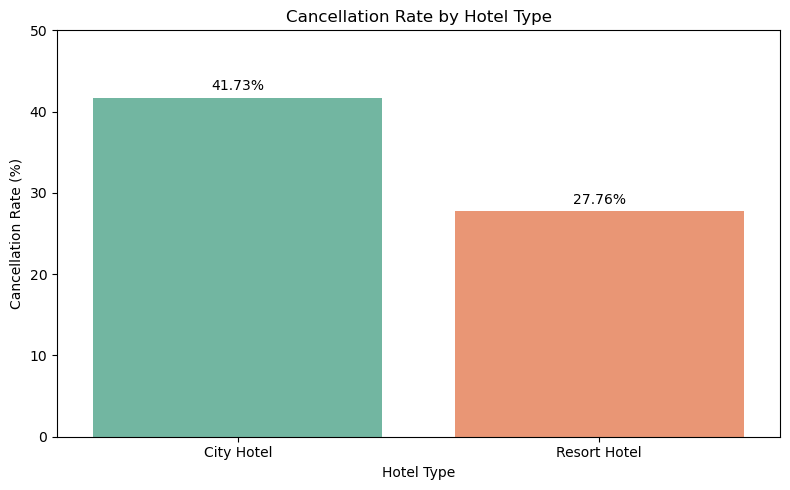

In [150]:

# Plot cancellation rates by hotel type
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cancellation_by_hotel.index,
    y=cancellation_by_hotel.values,
    hue=cancellation_by_hotel.index,
    palette='Set2',
    legend=False
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 50)
plt.tight_layout()
plt.show()


### Cancellation Rate by Hotel Type

City Hotel has a cancellation rate of **41.73%**, compared with **27.76%** for Resort Hotel. This represents a difference of approximately **13.96 percentage points**.

The higher cancellation rate at City Hotel suggests that cancellation risk should be examined more closely for this hotel type. Further analysis of lead time, market segment, and deposit type may help identify booking characteristics associated with this difference.

These results show an association and do not establish the cause of cancellations.

In [151]:

# Calculate cancellation rates by lead time group
cancellation_by_lead_time = (
    df.groupby('lead_time_group', observed=False)['is_canceled']
    .mean()
    .mul(100)
)

# Display the results in chronological order
cancellation_by_lead_time


lead_time_group
0-7 days         9.632331
8-30 days       27.863924
31-90 days      37.698372
Over 90 days    50.650290
Name: is_canceled, dtype: float64

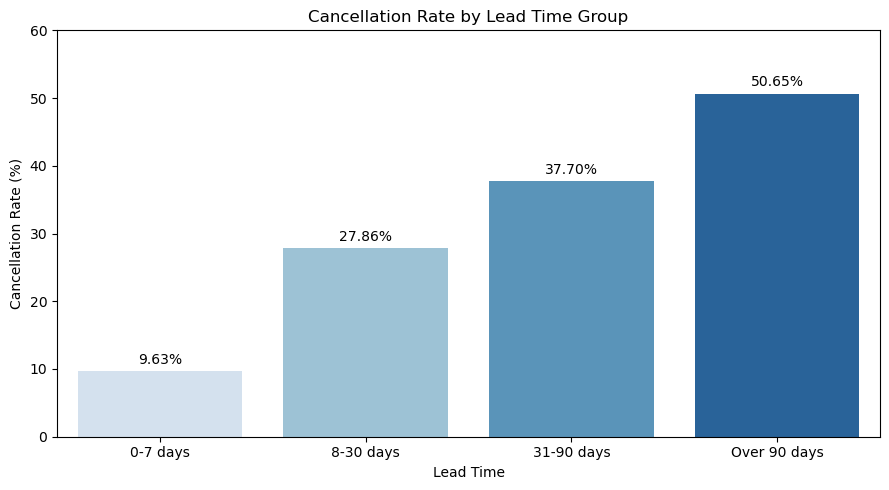

In [152]:

# Plot cancellation rates by lead time group
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=cancellation_by_lead_time.index,
    y=cancellation_by_lead_time.values,
    hue=cancellation_by_lead_time.index,
    palette='Blues',
    legend=False
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Cancellation Rate by Lead Time Group')
plt.xlabel('Lead Time')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 60)
plt.tight_layout()
plt.show()


### Cancellation Rate by Lead Time Group

Cancellation rates increase consistently across the lead time groups. Bookings made more than 90 days before arrival have the highest cancellation rate at **50.65%**, while bookings made 7 days or less before arrival have the lowest rate at **9.63%**.

This pattern suggests that bookings made further in advance are associated with greater cancellation risk. From a business perspective, hotels could consider monitoring long-lead-time bookings more closely when planning occupancy and room availability.

However, this analysis shows an association rather than a causal relationship.### Cancellation Rate by Lead Time Group

Cancellation rates increase consistently across the lead time groups. Bookings made more than 90 days before arrival have the highest cancellation rate at **50.65%**, while bookings made 7 days or less before arrival have the lowest rate at **9.63%**.

This pattern suggests that bookings made further in advance are associated with greater cancellation risk. From a business perspective, hotels could consider monitoring long-lead-time bookings more closely when planning occupancy and room availability.

However, this analysis shows an association rather than a causal relationship.

In [153]:

# Calculate cancellation rates by deposit type
cancellation_by_deposit = (
    df.groupby('deposit_type')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display cancellation rates
cancellation_by_deposit


deposit_type
Non Refund    99.362446
No Deposit    28.377022
Refundable    22.222222
Name: is_canceled, dtype: float64

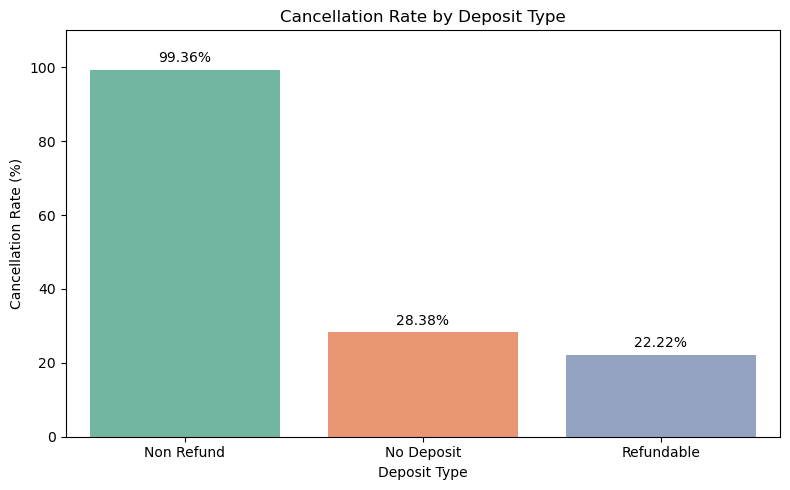

In [154]:

# Plot cancellation rates by deposit type
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=cancellation_by_deposit.index,
    y=cancellation_by_deposit.values,
    hue=cancellation_by_deposit.index,
    palette='Set2',
    legend=False
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Cancellation Rate by Deposit Type')
plt.xlabel('Deposit Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 110)
plt.tight_layout()
plt.show()


### Cancellation Rate by Deposit Type

Bookings with a `Non Refund` deposit type have a cancellation rate of **99.36%**, substantially higher than bookings with `No Deposit` (28.38%) and `Refundable` deposits (22.22%).

This is a striking association and warrants further investigation. Before drawing operational conclusions, the hotel should verify how deposit types were recorded and whether the observed pattern reflects booking policies, customer selection, or other factors.

The `Refundable` category contains only 162 bookings, so its cancellation rate should be interpreted with caution. These results do not establish that a deposit policy itself caused cancellations.

In [155]:

# Calculate cancellation rates by market segment
cancellation_by_segment = (
    df.groupby('market_segment')['is_canceled']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Display cancellation rates
cancellation_by_segment


market_segment
Undefined        100.000000
Groups            61.062036
Online TA         36.721143
Offline TA/TO     34.316033
Aviation          21.940928
Corporate         18.734655
Direct            15.341901
Complementary     13.055182
Name: is_canceled, dtype: float64

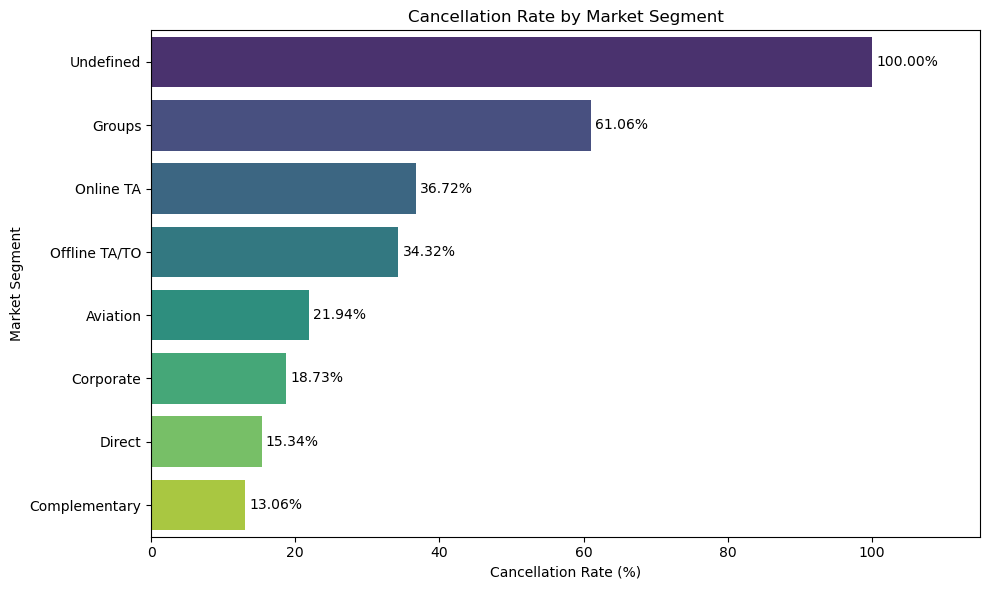

In [156]:

# Plot cancellation rates by market segment
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=cancellation_by_segment.values,
    y=cancellation_by_segment.index,
    hue=cancellation_by_segment.index,
    palette='viridis',
    legend=False
)

# Add percentage labels beside the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Cancellation Rate (%)')
plt.ylabel('Market Segment')
plt.xlim(0, 115)
plt.tight_layout()
plt.show()


In [157]:

# Calculate cancellation rates by hotel type and lead time group
cancellation_by_hotel_lead_time = (
    df.groupby(
        ['lead_time_group', 'hotel'],
        observed=False
    )['is_canceled']
    .mean()
    .mul(100)
    .reset_index(name='cancellation_rate')
)

# Display the results
cancellation_by_hotel_lead_time


,lead_time_group,hotel,cancellation_rate
0,0-7 days,City Hotel,12.203923
1,0-7 days,Resort Hotel,6.522712
2,8-30 days,City Hotel,30.906484
3,8-30 days,Resort Hotel,21.901342
4,31-90 days,City Hotel,39.909602
5,31-90 days,Resort Hotel,32.446323
6,Over 90 days,City Hotel,55.736260
7,Over 90 days,Resort Hotel,39.442356


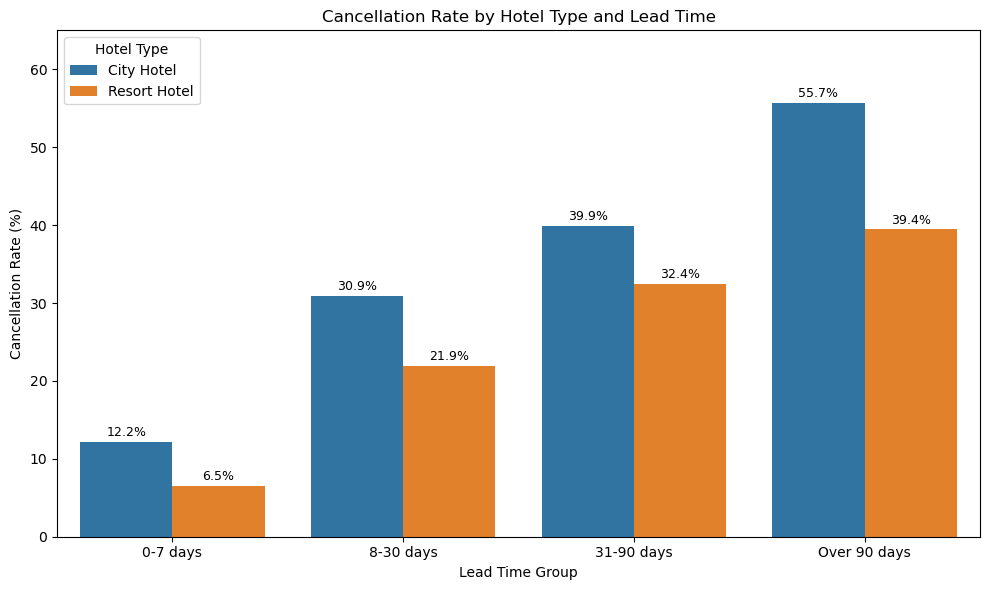

In [158]:

# Plot cancellation rates by hotel type and lead time group
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=cancellation_by_hotel_lead_time,
    x='lead_time_group',
    y='cancellation_rate',
    hue='hotel',
    order=['0-7 days', '8-30 days', '31-90 days', 'Over 90 days']
)

# Add percentage labels to each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2, fontsize=9)

plt.title('Cancellation Rate by Hotel Type and Lead Time')
plt.xlabel('Lead Time Group')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 65)
plt.legend(title='Hotel Type')
plt.tight_layout()
plt.show()


### Cancellation Rate by Hotel Type and Lead Time

Cancellation rates increase across all lead time groups for both hotel types. For City Hotel, the cancellation rate rises from **12.20%** for bookings made 0–7 days before arrival to **55.74%** for bookings made more than 90 days in advance. For Resort Hotel, it increases from **6.52%** to **39.44%**.

City Hotel has a higher cancellation rate than Resort Hotel in every lead time group. This suggests that both hotel type and booking lead time are useful dimensions for monitoring cancellation risk.

These findings show associations and do not establish that lead time or hotel type directly causes cancellations.

In [159]:

# Summarize bookings and cancellations by arrival month
monthly_cancellations = (
    df.groupby('arrival_date_month')
    .agg(
        total_bookings=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum')
    )
)

# Add cancellation rate
monthly_cancellations['cancellation_rate'] = (
    monthly_cancellations['canceled_bookings']
    / monthly_cancellations['total_bookings']
    * 100
)

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_cancellations = monthly_cancellations.reindex(month_order)

# Display the results
monthly_cancellations.round(2)


,total_bookings,canceled_bookings,cancellation_rate
arrival_date_month,,,
January,5929,1807,30.48
February,8068,2696,33.42
March,9794,3149,32.15
April,11089,4524,40.80
May,11791,4677,39.67
June,10939,4535,41.46
July,12661,4742,37.45
August,13877,5239,37.75
September,10508,4116,39.17


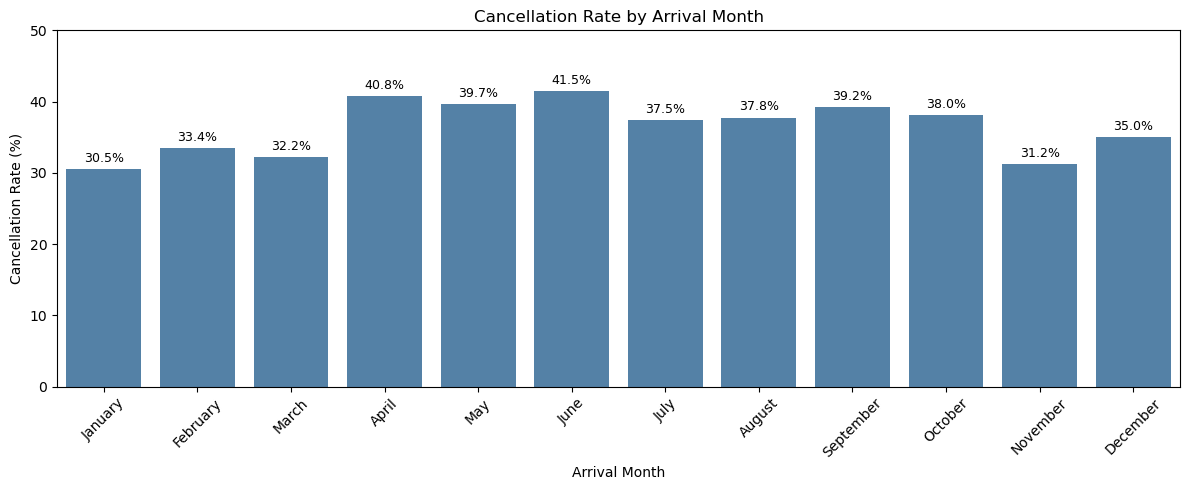

In [160]:

# Plot monthly cancellation rates by arrival month
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    x=monthly_cancellations.index,
    y=monthly_cancellations['cancellation_rate'],
    color='steelblue'
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

plt.title('Cancellation Rate by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.ylim(0, 50)
plt.tight_layout()
plt.show()


In [161]:
# Calculate cancellation rates by repeat guest status
repeat_guest_analysis = (
    df.groupby('is_repeated_guest')
    .agg(
        total_bookings=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
)

# Convert cancellation rates to percentages
repeat_guest_analysis['cancellation_rate'] *= 100

repeat_guest_analysis

,total_bookings,canceled_bookings,cancellation_rate
is_repeated_guest,,,
0,115580,43672,37.785084
1,3810,552,14.488189


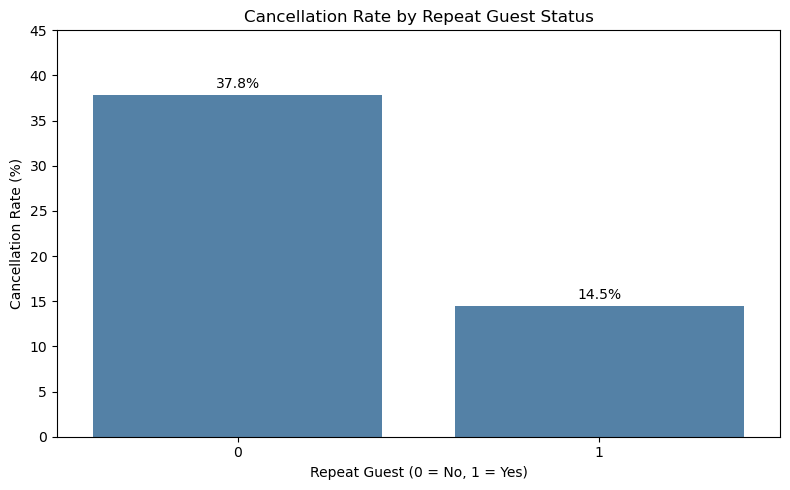

In [162]:
# Plot cancellation rates by repeat guest status
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=repeat_guest_analysis.reset_index(),
    x='is_repeated_guest',
    y='cancellation_rate',
    color='steelblue'
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Cancellation Rate by Repeat Guest Status')
plt.xlabel('Repeat Guest (0 = No, 1 = Yes)')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 45)
plt.tight_layout()
plt.show()

In [163]:
# Analyze cancellation rates by number of special requests
special_requests_analysis = (
    df.groupby('total_of_special_requests')
    .agg(
        total_bookings=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
)

# Convert cancellation rates to percentages
special_requests_analysis['cancellation_rate'] *= 100

special_requests_analysis

,total_bookings,canceled_bookings,cancellation_rate
total_of_special_requests,,,
0,70318,33556,47.720356
1,33226,7318,22.024920
2,12969,2866,22.098851
3,2497,446,17.861434
4,340,36,10.588235
5,40,2,5.000000


### Cancellation Rate by Number of Special Requests

Bookings with no special requests have the highest cancellation rate at **47.72%**. In comparison, bookings with one or two special requests have cancellation rates of approximately **22%**.

The cancellation rate generally decreases as the number of special requests increases. However, the group with five special requests contains only 40 bookings, so its 5.00% cancellation rate should be interpreted cautiously.

This pattern suggests an association between special requests and cancellation behavior. Further analysis is needed to determine whether other booking characteristics contribute to this relationship.

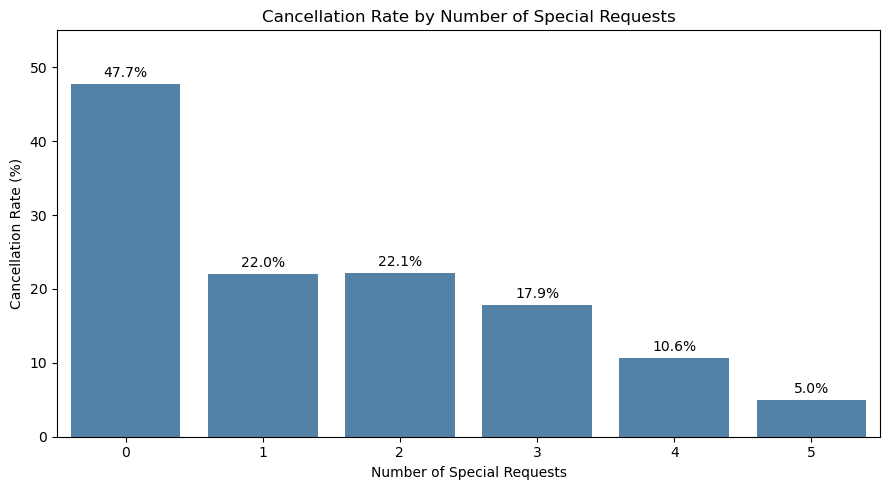

In [164]:
# Plot cancellation rates by number of special requests
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=special_requests_analysis.index,
    y=special_requests_analysis['cancellation_rate'],
    color='steelblue'
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Cancellation Rate by Number of Special Requests')
plt.xlabel('Number of Special Requests')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 55)
plt.tight_layout()
plt.show()

In [165]:
# Group bookings by waiting list status
df['waiting_list_status'] = df['days_in_waiting_list'].apply(
    lambda days: 'Had Waiting Time' if days > 0 else 'No Waiting Time'
)

# Calculate cancellation rates for each group
waiting_list_analysis = (
    df.groupby('waiting_list_status')
    .agg(
        total_bookings=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
)

# Convert cancellation rates to percentages
waiting_list_analysis['cancellation_rate'] *= 100

waiting_list_analysis

,total_bookings,canceled_bookings,cancellation_rate
waiting_list_status,,,
Had Waiting Time,3698,2359,63.791239
No Waiting Time,115692,41865,36.186599


### Cancellation Rate by Waiting List Status

Bookings with waiting time have a cancellation rate of **63.79%**, compared with **36.19%** for bookings without waiting time. This represents a difference of approximately **27.60 percentage points**.

Although bookings with waiting time show a substantially higher cancellation rate, this group contains only 3,698 bookings, compared with 115,692 bookings without waiting time.

This pattern identifies waiting-list status as a potential indicator for further investigation. However, the analysis shows an association and does not establish that waiting time causes cancellations.

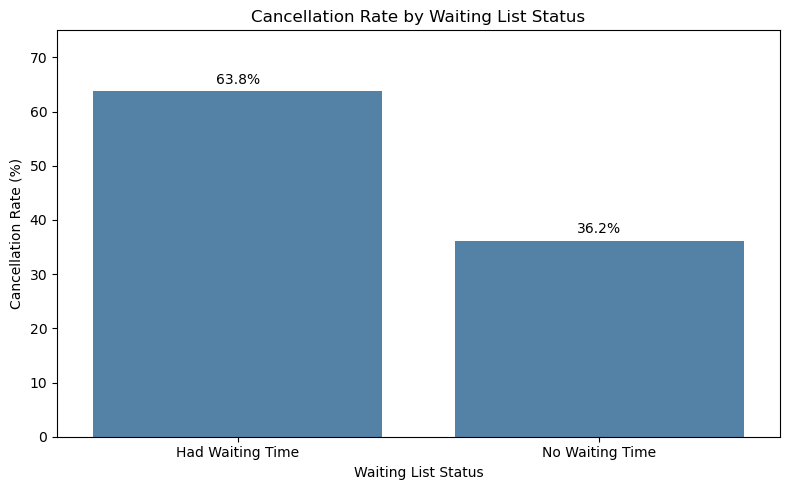

In [166]:
# Plot cancellation rates by waiting list status
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=waiting_list_analysis.reset_index(),
    x='waiting_list_status',
    y='cancellation_rate',
    color='steelblue'
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Cancellation Rate by Waiting List Status')
plt.xlabel('Waiting List Status')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 75)
plt.tight_layout()
plt.show()

In [167]:
# Identify bookings where the assigned room type differs from the reserved room type
df['room_type_changed'] = (
    df['reserved_room_type'] != df['assigned_room_type']
)

# Calculate cancellation rates by room type change status
room_change_analysis = (
    df.groupby('room_type_changed')
    .agg(
        total_bookings=('is_canceled', 'size'),
        canceled_bookings=('is_canceled', 'sum'),
        cancellation_rate=('is_canceled', 'mean')
    )
)

# Convert cancellation rates to percentages
room_change_analysis['cancellation_rate'] *= 100

room_change_analysis

,total_bookings,canceled_bookings,cancellation_rate
room_type_changed,,,
False,104473,43422,41.562892
True,14917,802,5.376416


### Cancellation Rate by Room Type Change

Bookings where the assigned room type differs from the reserved room type have a cancellation rate of **5.38%**, compared with **41.56%** for bookings where the room types are the same.

This is a substantial difference of approximately **36.19 percentage points**. However, the result should be interpreted cautiously because the assigned room type may reflect information recorded later in the booking process.

The observed association does not mean that changing a room type reduces cancellations. Further investigation is needed to understand how room assignment timing and reservation status affect this relationship.

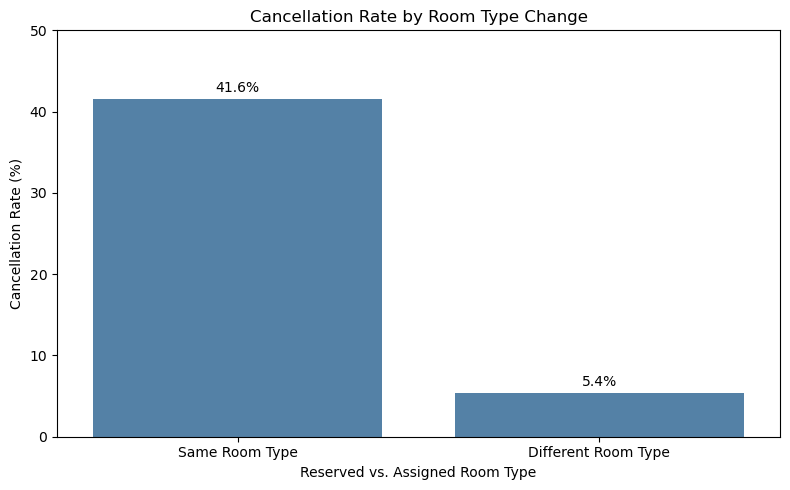

In [168]:
# Plot cancellation rates by room type change status
plt.figure(figsize=(8, 5))

plot_data = room_change_analysis.reset_index()
plot_data['room_type_changed'] = plot_data['room_type_changed'].map({
    False: 'Same Room Type',
    True: 'Different Room Type'
})

ax = sns.barplot(
    data=plot_data,
    x='room_type_changed',
    y='cancellation_rate',
    color='steelblue'
)

# Add percentage labels above the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('Cancellation Rate by Room Type Change')
plt.xlabel('Reserved vs. Assigned Room Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

In [169]:
# Calculate key performance indicators for the hotel booking analysis
total_bookings = len(df)
canceled_bookings = df['is_canceled'].sum()
cancellation_rate = df['is_canceled'].mean() * 100

completed_bookings = (
    df['reservation_status'] == 'Check-Out'
).sum()

city_cancellation_rate = (
    df.loc[df['hotel'] == 'City Hotel', 'is_canceled'].mean() * 100
)

resort_cancellation_rate = (
    df.loc[df['hotel'] == 'Resort Hotel', 'is_canceled'].mean() * 100
)

kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Bookings',
        'Canceled Bookings',
        'Overall Cancellation Rate (%)',
        'Completed Bookings',
        'City Hotel Cancellation Rate (%)',
        'Resort Hotel Cancellation Rate (%)'
    ],
    'Value': [
        total_bookings,
        canceled_bookings,
        round(cancellation_rate, 2),
        completed_bookings,
        round(city_cancellation_rate, 2),
        round(resort_cancellation_rate, 2)
    ]
})

kpi_summary

,Metric,Value
0,Total Bookings,119390.00
1,Canceled Bookings,44224.00
2,Overall Cancellation Rate (%),37.04
3,Completed Bookings,75166.00
4,City Hotel Cancellation Rate (%),41.73
5,Resort Hotel Cancellation Rate (%),27.76


## Key Performance Indicators

The dataset contains **119,390 bookings**, of which **44,224 were canceled**, resulting in an overall cancellation rate of **37.04%**. A total of **75,166 bookings** have a reservation status of `Check-Out`.

Cancellation rates differ between the two hotel types. City Hotel has a cancellation rate of **41.73%**, compared with **27.76%** for Resort Hotel, a difference of approximately **13.96 percentage points**.

These KPIs provide an overview of booking outcomes and highlight City Hotel as a priority for further cancellation-risk investigation. However, cancellation rates alone do not measure actual revenue loss or establish the causes of cancellations.

## Business Insights and Recommendations

### 1. City Hotel Has a Higher Cancellation Rate

City Hotel has a cancellation rate of **41.73%**, compared with **27.76%** for Resort Hotel.

**Recommendation:** Investigate City Hotel bookings more closely, especially by lead time, market segment, and deposit type, to identify high-risk booking patterns.

### 2. Longer Lead Times Are Associated with Higher Cancellation Rates

Bookings made more than 90 days before arrival have a cancellation rate of **50.65%**, compared with **9.63%** for bookings made within 7 days of arrival.

**Recommendation:** Consider targeted confirmation messages and flexible cancellation-management strategies for bookings made far in advance.

### 3. Cancellation Rates Differ Across Market Segments

The Groups segment has a cancellation rate of **61.06%**, while Online TA has a rate of **36.72%**. Online TA also accounts for the largest number of canceled bookings.

**Recommendation:** Review cancellation patterns and booking conditions by market segment. Prioritize segments with both high cancellation rates and substantial booking volumes.

### 4. Deposit Type Is Strongly Associated with Cancellation Outcomes

Bookings with a Non Refund deposit type have a cancellation rate of **99.36%**.

**Recommendation:** Validate the meaning and recording of deposit categories before using this result for business decisions. The unusually high rate warrants further investigation and should not be interpreted as evidence that non-refundable deposits cause cancellations.

### 5. Repeat Guests Have Lower Cancellation Rates

Repeated guests have a cancellation rate of **14.49%**, compared with **37.79%** for non-repeated guests.

**Recommendation:** Explore customer-retention initiatives and investigate whether repeat-guest behavior can help improve cancellation-risk assessment.

### 6. Special Requests and Waiting-List Status Identify Different Booking Patterns

Bookings with no special requests have a cancellation rate of **47.72%**, while bookings with at least one day on the waiting list have a cancellation rate of **63.79%**.

**Recommendation:** Investigate these booking groups further, while considering other characteristics such as hotel type, lead time, and market segment. These relationships do not establish causation.

### Overall Business Conclusion

The analysis identifies several booking characteristics associated with cancellation risk, including hotel type, lead time, market segment, deposit type, repeat-guest status, and waiting-list status.

These findings can help prioritize further investigation and support more targeted booking-management strategies. However, the results are descriptive and do not establish causal relationships. Additional validation and testing would be needed before implementing policy changes or estimating financial benefits.